# Resolved silica liquid offsets between experiments and DFT

This notebook calculates the difference, with uncertainties, between experimental PVT shock data for liquid SiO₂ and DFT calculations using GGA-PBE and LDA from
* Geng, M., & Mohn, C. E. (2024). Ab initio constraints on the melting of silica at high pressures up to 500 GPa. Physical Review B, 109(2), 024106. https://doi.org/10.1103/PhysRevB.109.024106
* Karki, B. B., Bhattarai, D., & Stixrude, L. (2007). First-principles simulations of liquid silica: Structural and dynamical behavior at high pressure. Physical Review B, 76(10), 104205. https://doi.org/10.1103/PhysRevB.76.104205

Updated 10/13/2025 sts

In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
%run -i scripts/intersection.py # intersection function
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'DFT-'

# gm24mc set in load_silica_data.py


In [2]:
import matplotlib as mpl
import scipy as sp
from scipy import linalg
from scipy.optimize import fsolve

## DFT with GGA-PBE


Using the PBE melt curve liquidus density from Geng & Mohn 2024. The melt curve P-T curve was derived using the 2-phase method. Liquid on the melt curve density-pressure points were obtained from the authors. Note that the P-T states for the liquidus densities are generally a little too hot. See {ref}`GM24-data`.

To detemine the offset between PBE and experiments:
* Find the P-T points where the liquid branch of the experimental Hugoniots intersect the PBE P-T melt curve.
* Compare the PBE liquidus densities to the known Hugoniot densities.
* Comparisons can be made for fused silica, quartz, and coesite.


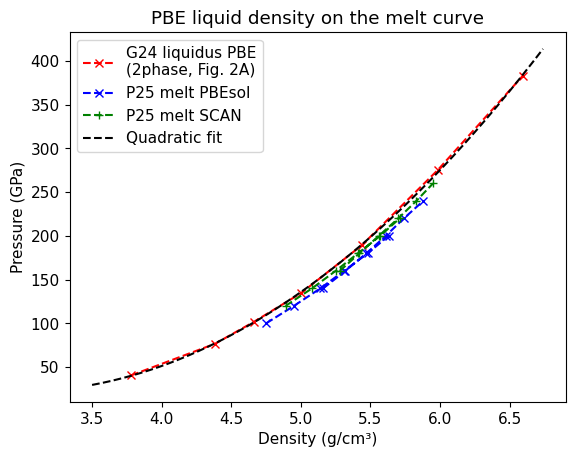

In [3]:

plt.plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'x--',color='red',label=G24mclrho['lab']+'\n(2phase, Fig. 2A)')

plt.plot(eosdat_list[P25mcpbe['id']].rho_l,eosdat_list[P25mcpbe['id']].P,'x--',color='b',label=P25mcpbe['lab'])
plt.plot(eosdat_list[P25mcscan['id']].rho_l,eosdat_list[P25mcscan['id']].P,'+--',color='g',label=P25mcscan['lab'])

plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')

res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)

xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
plt.plot(xrho,ypres,'k--',label='Quadratic fit')
plt.title('PBE liquid density on the melt curve')
plt.legend()
plt.show()


In [4]:

# find where P-T crosses
fs_PT_cross = intersection(gm24mc.P,gm24mc.T,fs_hug_liq.P,fs_hug_liq.T)
qtz_PT_cross = intersection(gm24mc.P,gm24mc.T,qtz_hug_liq.P,qtz_hug_liq.T)
cst_PT_cross = intersection(gm24mc.P,gm24mc.T,cst_hug_liq.P,cst_hug_liq.T)

fs_rho_cross = np.interp(fs_PT_cross[0],fs_hug_liq.P,fs_hug_liq.rho)
qtz_rho_cross = np.interp(qtz_PT_cross[0],qtz_hug_liq.P,qtz_hug_liq.rho)
cst_rho_cross = np.interp(cst_PT_cross[0],cst_hug_liq.P,cst_hug_liq.rho)

# Fig 2 Geng et al. 2024 model densities
fs_rho_model = np.interp(fs_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)
qtz_rho_model = np.interp(qtz_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)
cst_rho_model = np.interp(cst_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)

fs_rho_model = np.interp(fs_PT_cross[0],ypres,xrho)
qtz_rho_model = np.interp(qtz_PT_cross[0],ypres,xrho)
cst_rho_model = np.interp(cst_PT_cross[0],ypres,xrho)


print(fs_rho_cross-fs_rho_model)
print(qtz_rho_cross-qtz_rho_model)
print(cst_rho_cross-cst_rho_model)

diff_arr = np.asarray([fs_rho_cross-fs_rho_model,qtz_rho_cross-qtz_rho_model,cst_rho_cross-cst_rho_model])
diff_mean = np.mean(diff_arr)
diff_std = np.std(diff_arr)
print(diff_mean,diff_std)
G24_rshift = diff_mean
G24_rshift_std = diff_std

[0.16603327]
[0.1210586]
[0.07439566]
0.12049584241245152 0.03741301490098057


## Calculate Monte-Carlo uncertainties for Hugoniot Fits

First determine the desired particle velocity range for MC calculations.

<Figure size 800x600 with 0 Axes>

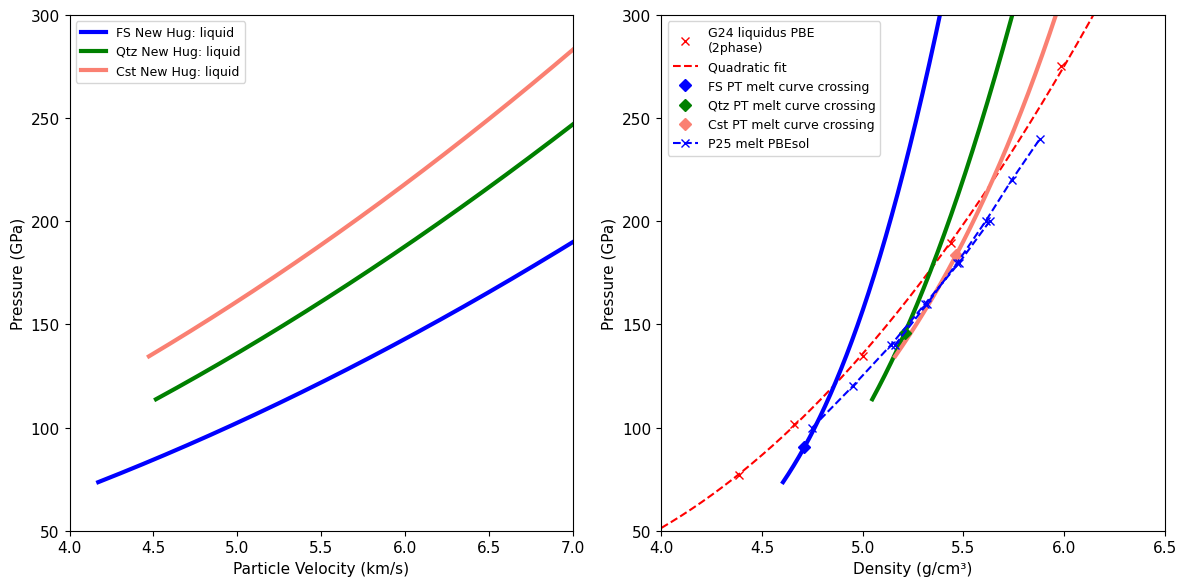

In [5]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(1, 2,figsize=(12,6))
plt.rcParams['lines.markersize'] = mks


whu=3

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[0].plot(fs_hug_liq.up[indfs],fs_hug_liq.P[indfs],'b-',label='FS New Hug: liquid',linewidth=whu)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[0].plot(qtz_hug_liq.up[indqtz],qtz_hug_liq.P[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[0].plot(cst_hug_liq.up[indcst],cst_hug_liq.P[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[0].set_xlim(4,7)
ax[0].set_ylim(50,300)
ax[0].set_ylabel('Pressure (GPa)')
ax[0].set_xlabel('Particle Velocity (km/s)')
#ax[0].text(55,6650,'A')
ax[0].legend(fontsize=lfss)


ax[1].plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'x',color='red',label=G24mclrho['lab']+'\n(2phase)')
ax[1].plot(xrho,ypres,'--',color='red',label='Quadratic fit')

#ax[1].plot(eosdat_list[G24mclrho['id']].rho_liquid+diff_mean,eosdat_list[G24mclrho['id']].P_liquid,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
#ax[1].plot(xrho+diff_mean,ypres,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[1].plot(fs_hug_liq.rho[indfs],fs_hug_liq.P[indfs],'b-',linewidth=whu)#,label='FS Hugoniot')
ax[1].plot(qtz_hug_liq.rho[indqtz],qtz_hug_liq.P[indqtz],'g-',linewidth=whu)#,label='Qtz Hugoniot')
ax[1].plot(cst_hug_liq.rho[indcst],cst_hug_liq.P[indcst],'-',color='salmon',linewidth=whu)#,label='Cst Hugoniot')
ax[1].plot(fs_rho_cross,fs_PT_cross[0],'bD',label='FS PT melt curve crossing')
ax[1].plot(qtz_rho_cross,qtz_PT_cross[0],'gD',label='Qtz PT melt curve crossing')
ax[1].plot(cst_rho_cross,cst_PT_cross[0],'D',color='salmon',label='Cst PT melt curve crossing')

plt.plot(eosdat_list[P25mcpbe['id']].rho_l,eosdat_list[P25mcpbe['id']].P,'x--',color='b',label=P25mcpbe['lab'])

#ax[1].fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2)

ax[1].set_ylim(50,300)
ax[1].set_xlim(4,6.5)
#ax[1].text(4.1,225,'B')

ax[1].set_ylabel('Pressure (GPa)')
ax[1].set_xlabel('Density (g/cm³)')
ax[1].legend(fontsize=lfss)

fig.tight_layout()
#plt.savefig(outputfigpath+'Geng24-density-shift.pdf')
#plt.savefig(figurefigpath+'Geng24-density-shift.pdf')
plt.show()

## Set up Monte Carlo for error envelopes

In [6]:
%%capture 
## Fused silica PVT Hugoniot
print('Fused silia PTV Hugoniot Uncertainties')
nsteps = 10000
nupind = 100

upmin=fs_wiggle_up2
upmax=12
mcuparr = np.linspace(upmin,upmax,nupind)
print(mcuparr)
print('Number of MC iterations for each particle velocity: ',nsteps)
print('Number of particle velocities: ',len(mcuparr))


print('Us-up fit: ',fs_fit_liq0.curvetype)
print('T-Us fit: ',fs_fitTus_liq0.curvetype)

print('Reference density = ',fs_fit_liq0.rho_ref)
print('Reference density uncertainty = ',fs_fit_liq0.rho_ref_std)
#print('WARNING: test sensitivity to rho0 uncertainty later')


###========================================================================
# INITIALIZE MC DATA STRUCTURE
# FUSED SILICA
dat_mc = hpmc.HPeos_MC()

dat_mc.npts = nsteps  
dat_mc.up_ind = mcuparr 

upus_fit = deepcopy(fs_fit_liq0)
upus_fit.rho_ref_std = .01
print('Using rho0 std = 0.01 g/cm3')
ust_fit = deepcopy(fs_fitTus_liq0)

###========================================================================
# BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS

# us-up fit
# The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
dat_lmat_upus = sp.linalg.cholesky(upus_fit.cov,lower=True) 
dat_lmat_ust = sp.linalg.cholesky(ust_fit.cov,lower=True) 

dat_mc.us_mean   = np.zeros(nupind)
dat_mc.p_mean    = np.zeros(nupind)
dat_mc.rho_mean  = np.zeros(nupind)
dat_mc.rho0_mean  = np.zeros(nupind)
dat_mc.t_mean    = np.zeros(nupind)
dat_mc.us_std   = np.zeros(nupind)
dat_mc.p_std    = np.zeros(nupind)
dat_mc.rho_std  = np.zeros(nupind)
dat_mc.rho0_std  = np.zeros(nupind)
dat_mc.t_std    = np.zeros(nupind)

print(upus_fit.filename)
print('Coefs = ',upus_fit.a)

# loop over independent variable up
for iup in range(len(dat_mc.up_ind)):
    # set independent variable
    dat_mc.up   = np.zeros(nsteps)+dat_mc.up_ind[iup]
    # set up MC variables
    dat_mc.rho0 = np.zeros(nsteps)
    dat_mc.us   = np.zeros(nsteps)
    dat_mc.p    = np.zeros(nsteps)
    dat_mc.rho  = np.zeros(nsteps)
    dat_mc.t    = np.zeros(nsteps)

    # MC steps for each independent variable
    temp_fit = hp.HPeos_Fit()

    # up -> Us, P, V points
    # Us -> T points
    for imc in range(nsteps):      
        # uncertainty on initial density
        dat_mc.rho0[imc] = upus_fit.rho_ref + upus_fit.rho_ref_std*np.random.randn()

        # uncertainty on curve fit to us-up
        ncoefs = len(upus_fit.a)
        temp_mat=np.random.randn(ncoefs)
        bmat=np.matmul(dat_lmat_upus,temp_mat)
        
        a_mc = np.zeros(ncoefs)
        for ia in range(ncoefs):
            a_mc[ia] = upus_fit.a[ia]+bmat[ia]
        # fill generic fit data structure
        temp_fit.a = a_mc
        temp_fit.curvetype = upus_fit.curvetype
        dat_mc.us[imc]=temp_fit.calcf(dat_mc.up[imc])
        #print(temp_fit.a)

        # uncertainty on curve fit to T-us
        ncoefs = len(ust_fit.a)
        temp_mat=np.random.randn(ncoefs)
        bmat=np.matmul(dat_lmat_ust,temp_mat)
        
        a_mc = np.zeros(ncoefs)
        for ia in range(ncoefs):
            a_mc[ia] = ust_fit.a[ia]+bmat[ia]
        # fill generic fit data structure
        temp_fit.a = a_mc
        temp_fit.curvetype = ust_fit.curvetype
        dat_mc.t[imc]=temp_fit.calcf(dat_mc.us[imc])
        #print(temp_fit.a)
        
    # for each independent variable
    # calculate P and rho for the MC batch
    dat_mc.calcPrho()
    # The mean and std for each MC batch
    dat_mc.rho0_mean[iup] = np.mean(dat_mc.rho0)
    dat_mc.rho0_std[iup] = np.std(dat_mc.rho0)
    dat_mc.us_mean[iup] = np.mean(dat_mc.us)
    dat_mc.us_std[iup] = np.std(dat_mc.us)
    dat_mc.p_mean[iup] = np.mean(dat_mc.p)
    dat_mc.p_std[iup] = np.std(dat_mc.p)
    dat_mc.rho_mean[iup] = np.mean(dat_mc.rho)
    dat_mc.rho_std[iup] = np.std(dat_mc.rho)
    dat_mc.t_mean[iup] = np.mean(dat_mc.t)
    dat_mc.t_std[iup] = np.std(dat_mc.t)

    print(dat_mc.up_ind[iup],dat_mc.us_mean[iup],dat_mc.us_std[iup],upus_fit.calcf(dat_mc.up_ind[iup]),dat_mc.rho0_mean[iup],dat_mc.rho0_std[iup],dat_mc.p_mean[iup],dat_mc.rho_mean[iup],dat_mc.t_mean[iup],dat_mc.t_std[iup])

if 1:
    # free up memory
    steps = 1
    dat_mc.rho0 = np.zeros(steps)
    dat_mc.us   = np.zeros(steps)
    dat_mc.p    = np.zeros(steps)
    dat_mc.rho  = np.zeros(steps)
    dat_mc.t    = np.zeros(steps)

###========================================================================
# END SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS

fs_mc = deepcopy(dat_mc)

In [7]:
%%capture 
## alpha-Quartz PVT Hugoniot
print('Alpha-Quartz PTV Hugoniot Uncertainties')
nsteps = 10000
nupind = 100

upmin=qtz_wiggle_up2
upmax=10
mcuparr = np.linspace(upmin,upmax,nupind)
print(mcuparr)
print('Number of MC iterations for each particle velocity: ',nsteps)
print('Number of particle velocities: ',len(mcuparr))


print('Us-up fit: ',qtz_fit_liq0.curvetype)
print('T-Us fit: ',qtz_fitTus_liq0.curvetype)

print('Reference density = ',qtz_fit_liq0.rho_ref)
print('Reference density uncertainty = ',qtz_fit_liq0.rho_ref_std)
#print('WARNING: test sensitivity to rho0 uncertainty later')


###========================================================================
# INITIALIZE MC DATA STRUCTURE
# FUSED SILICA
dat_mc = hpmc.HPeos_MC()

dat_mc.npts = nsteps  
dat_mc.up_ind = mcuparr 

upus_fit = deepcopy(qtz_fit_liq0)
upus_fit.rho_ref_std = .01
print('Using rho0 std = 0.01 g/cm3')
ust_fit = deepcopy(qtz_fitTus_liq0)

###========================================================================
# BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS

# us-up fit
# The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
dat_lmat_upus = sp.linalg.cholesky(upus_fit.cov,lower=True) 
dat_lmat_ust = sp.linalg.cholesky(ust_fit.cov,lower=True) 

dat_mc.us_mean   = np.zeros(nupind)
dat_mc.p_mean    = np.zeros(nupind)
dat_mc.rho_mean  = np.zeros(nupind)
dat_mc.rho0_mean  = np.zeros(nupind)
dat_mc.t_mean    = np.zeros(nupind)
dat_mc.us_std   = np.zeros(nupind)
dat_mc.p_std    = np.zeros(nupind)
dat_mc.rho_std  = np.zeros(nupind)
dat_mc.rho0_std  = np.zeros(nupind)
dat_mc.t_std    = np.zeros(nupind)

print(upus_fit.filename)
print('Coefs = ',upus_fit.a)
print(ust_fit.filename)
print('Coefs = ',ust_fit.a)

# loop over independent variable up
for iup in range(len(dat_mc.up_ind)):
    # set independent variable
    dat_mc.up   = np.zeros(nsteps)+dat_mc.up_ind[iup]
    # set up MC variables
    dat_mc.rho0 = np.zeros(nsteps)
    dat_mc.us   = np.zeros(nsteps)
    dat_mc.p    = np.zeros(nsteps)
    dat_mc.rho  = np.zeros(nsteps)
    dat_mc.t    = np.zeros(nsteps)

    # MC steps for each independent variable
    temp_fit = hp.HPeos_Fit()

    # up -> Us, P, V points
    # Us -> T points
    for imc in range(nsteps):      
        # uncertainty on initial density
        dat_mc.rho0[imc] = upus_fit.rho_ref + upus_fit.rho_ref_std*np.random.randn()

        # uncertainty on curve fit to us-up
        ncoefs = len(upus_fit.a)
        temp_mat=np.random.randn(ncoefs)
        bmat=np.matmul(dat_lmat_upus,temp_mat)
        
        a_mc = np.zeros(ncoefs)
        for ia in range(ncoefs):
            a_mc[ia] = upus_fit.a[ia]+bmat[ia]
        # fill generic fit data structure
        temp_fit.a = a_mc
        temp_fit.curvetype = upus_fit.curvetype
        dat_mc.us[imc]=temp_fit.calcf(dat_mc.up[imc])
        #print(temp_fit.a)

        # uncertainty on curve fit to T-us
        ncoefs = len(ust_fit.a)
        temp_mat=np.random.randn(ncoefs)
        bmat=np.matmul(dat_lmat_ust,temp_mat)
        
        a_mc = np.zeros(ncoefs)
        for ia in range(ncoefs):
            a_mc[ia] = ust_fit.a[ia]+bmat[ia]
        # fill generic fit data structure
        temp_fit.a = a_mc
        temp_fit.curvetype = ust_fit.curvetype
        dat_mc.t[imc]=temp_fit.calcf(dat_mc.us[imc])
        #print(temp_fit.a)
        
    # for each independent variable
    # calculate P and rho for the MC batch
    dat_mc.calcPrho()
    # The mean and std for each MC batch
    dat_mc.rho0_mean[iup] = np.mean(dat_mc.rho0)
    dat_mc.rho0_std[iup] = np.std(dat_mc.rho0)
    dat_mc.us_mean[iup] = np.mean(dat_mc.us)
    dat_mc.us_std[iup] = np.std(dat_mc.us)
    dat_mc.p_mean[iup] = np.mean(dat_mc.p)
    dat_mc.p_std[iup] = np.std(dat_mc.p)
    dat_mc.rho_mean[iup] = np.mean(dat_mc.rho)
    dat_mc.rho_std[iup] = np.std(dat_mc.rho)
    dat_mc.t_mean[iup] = np.mean(dat_mc.t)
    dat_mc.t_std[iup] = np.std(dat_mc.t)

    print(dat_mc.up_ind[iup],dat_mc.us_mean[iup],dat_mc.us_std[iup],upus_fit.calcf(dat_mc.up_ind[iup]),dat_mc.rho0_mean[iup],dat_mc.rho0_std[iup],dat_mc.p_mean[iup],dat_mc.rho_mean[iup],dat_mc.t_mean[iup],dat_mc.t_std[iup])

if 1:
    # free up memory
    steps = 1
    dat_mc.rho0 = np.zeros(steps)
    dat_mc.us   = np.zeros(steps)
    dat_mc.p    = np.zeros(steps)
    dat_mc.rho  = np.zeros(steps)
    dat_mc.t    = np.zeros(steps)

###========================================================================
# END SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS

qtz_mc = deepcopy(dat_mc)

In [8]:
%%capture 
## Coesite PVT Hugoniot
print('Coesite PTV Hugoniot Uncertainties')
nsteps = 10000
nupind = 100

upmin=cst_wiggle_up2
upmax=7
mcuparr = np.linspace(upmin,upmax,nupind)
print(mcuparr)
print('Number of MC iterations for each particle velocity: ',nsteps)
print('Number of particle velocities: ',len(mcuparr))


print('Us-up fit: ',cst_fit_liq0.curvetype)
print('T-Us fit: ',cst_fitTus_liq0.curvetype)

print('Reference density = ',cst_fit_liq0.rho_ref)
print('Reference density uncertainty = ',cst_fit_liq0.rho_ref_std)
#print('WARNING: test sensitivity to rho0 uncertainty later')


###========================================================================
# INITIALIZE MC DATA STRUCTURE
# FUSED SILICA
dat_mc = hpmc.HPeos_MC()

dat_mc.npts = nsteps  
dat_mc.up_ind = mcuparr 

upus_fit = deepcopy(cst_fit_liq0)
upus_fit.rho_ref_std = .03
print('Using rho0 std = 0.03 g/cm3')
ust_fit = deepcopy(cst_fitTus_liq0)

###========================================================================
# BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS

# us-up fit
# The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
dat_lmat_upus = sp.linalg.cholesky(upus_fit.cov,lower=True) 
dat_lmat_ust = sp.linalg.cholesky(ust_fit.cov,lower=True) 

dat_mc.us_mean   = np.zeros(nupind)
dat_mc.p_mean    = np.zeros(nupind)
dat_mc.rho_mean  = np.zeros(nupind)
dat_mc.rho0_mean  = np.zeros(nupind)
dat_mc.t_mean    = np.zeros(nupind)
dat_mc.us_std   = np.zeros(nupind)
dat_mc.p_std    = np.zeros(nupind)
dat_mc.rho_std  = np.zeros(nupind)
dat_mc.rho0_std  = np.zeros(nupind)
dat_mc.t_std    = np.zeros(nupind)

print(upus_fit.filename)
print('Coefs = ',upus_fit.a)
print(ust_fit.filename)
print('Coefs = ',ust_fit.a)

# loop over independent variable up
for iup in range(len(dat_mc.up_ind)):
    # set independent variable
    dat_mc.up   = np.zeros(nsteps)+dat_mc.up_ind[iup]
    # set up MC variables
    dat_mc.rho0 = np.zeros(nsteps)
    dat_mc.us   = np.zeros(nsteps)
    dat_mc.p    = np.zeros(nsteps)
    dat_mc.rho  = np.zeros(nsteps)
    dat_mc.t    = np.zeros(nsteps)

    # MC steps for each independent variable
    temp_fit = hp.HPeos_Fit()

    # up -> Us, P, V points
    # Us -> T points
    for imc in range(nsteps):      
        # uncertainty on initial density
        dat_mc.rho0[imc] = upus_fit.rho_ref + upus_fit.rho_ref_std*np.random.randn()

        # uncertainty on curve fit to us-up
        ncoefs = len(upus_fit.a)
        temp_mat=np.random.randn(ncoefs)
        bmat=np.matmul(dat_lmat_upus,temp_mat)
        
        a_mc = np.zeros(ncoefs)
        for ia in range(ncoefs):
            a_mc[ia] = upus_fit.a[ia]+bmat[ia]
        # fill generic fit data structure
        temp_fit.a = a_mc
        temp_fit.curvetype = upus_fit.curvetype
        dat_mc.us[imc]=temp_fit.calcf(dat_mc.up[imc])
        #print(temp_fit.a)

        # uncertainty on curve fit to T-us
        ncoefs = len(ust_fit.a)
        temp_mat=np.random.randn(ncoefs)
        bmat=np.matmul(dat_lmat_ust,temp_mat)
        
        a_mc = np.zeros(ncoefs)
        for ia in range(ncoefs):
            a_mc[ia] = ust_fit.a[ia]+bmat[ia]
        # fill generic fit data structure
        temp_fit.a = a_mc
        temp_fit.curvetype = ust_fit.curvetype
        dat_mc.t[imc]=temp_fit.calcf(dat_mc.us[imc])
        #print(temp_fit.a)
        
    # for each independent variable
    # calculate P and rho for the MC batch
    dat_mc.calcPrho()
    # The mean and std for each MC batch
    dat_mc.rho0_mean[iup] = np.mean(dat_mc.rho0)
    dat_mc.rho0_std[iup] = np.std(dat_mc.rho0)
    dat_mc.us_mean[iup] = np.mean(dat_mc.us)
    dat_mc.us_std[iup] = np.std(dat_mc.us)
    dat_mc.p_mean[iup] = np.mean(dat_mc.p)
    dat_mc.p_std[iup] = np.std(dat_mc.p)
    dat_mc.rho_mean[iup] = np.mean(dat_mc.rho)
    dat_mc.rho_std[iup] = np.std(dat_mc.rho)
    dat_mc.t_mean[iup] = np.mean(dat_mc.t)
    dat_mc.t_std[iup] = np.std(dat_mc.t)

    print(dat_mc.up_ind[iup],dat_mc.us_mean[iup],dat_mc.us_std[iup],upus_fit.calcf(dat_mc.up_ind[iup]),dat_mc.rho0_mean[iup],dat_mc.rho0_std[iup],dat_mc.p_mean[iup],dat_mc.rho_mean[iup],dat_mc.t_mean[iup],dat_mc.t_std[iup])

if 1:
    # free up memory
    steps = 1
    dat_mc.rho0 = np.zeros(steps)
    dat_mc.us   = np.zeros(steps)
    dat_mc.p    = np.zeros(steps)
    dat_mc.rho  = np.zeros(steps)
    dat_mc.t    = np.zeros(steps)

###========================================================================
# END SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS

cst_mc = deepcopy(dat_mc)

<Figure size 800x600 with 0 Axes>

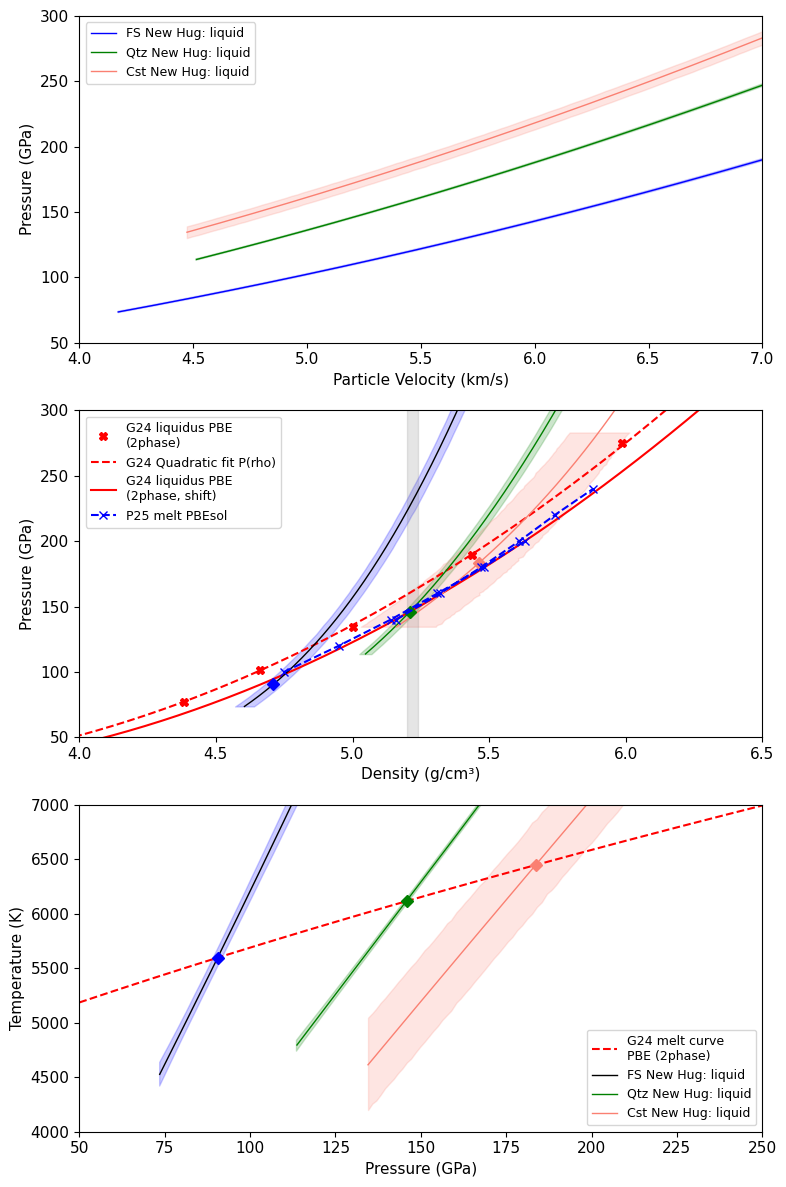

In [9]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(3, 1,figsize=(8,12))
plt.rcParams['lines.markersize'] = mks


whu=1

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
xi=0
ax[xi].plot(fs_hug_liq.up[indfs],fs_hug_liq.P[indfs],'b-',label='FS New Hug: liquid',linewidth=whu)
ax[xi].fill_between(fs_mc.up_ind,fs_mc.p_mean-fs_mc.p_std,fs_mc.p_mean+fs_mc.p_std,color='blue',alpha=.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.up[indqtz],qtz_hug_liq.P[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
ax[xi].fill_between(qtz_mc.up_ind,qtz_mc.p_mean-qtz_mc.p_std,qtz_mc.p_mean+fs_mc.p_std,color='green',alpha=.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.up[indcst],cst_hug_liq.P[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[xi].fill_between(cst_mc.up_ind,cst_mc.p_mean-cst_mc.p_std,cst_mc.p_mean+cst_mc.p_std,color='salmon',alpha=.2)
ax[xi].set_xlim(4,7)
ax[xi].set_ylim(50,300)
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
#ax[xi].text(55,6650,'A')
ax[xi].legend(fontsize=lfss)

xi=1
ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'X',color='red',label=G24mclrho['lab']+'\n(2phase)')
res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)
xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
ax[xi].plot(xrho,ypres,'--',color='red',label='G24 Quadratic fit P(rho)')

#ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid+diff_mean,eosdat_list[G24mclrho['id']].P_liquid,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].plot(xrho+diff_mean,ypres,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].plot(fs_hug_liq.rho[indfs],fs_hug_liq.P[indfs],'k-',linewidth=1)#,label='FS Hugoniot')
ax[xi].fill_betweenx(fs_mc.p_mean,fs_mc.rho_mean-fs_mc.rho_std,fs_mc.rho_mean+fs_mc.rho_std,color='blue',alpha=.2)

ax[xi].plot(qtz_hug_liq.rho[indqtz],qtz_hug_liq.P[indqtz],'g-',linewidth=whu)#,label='Qtz Hugoniot')
ax[xi].fill_betweenx(qtz_mc.p_mean,qtz_mc.rho_mean-qtz_mc.rho_std,qtz_mc.rho_mean+qtz_mc.rho_std,color='green',alpha=.2)

ax[xi].plot(cst_hug_liq.rho[indcst],cst_hug_liq.P[indcst],'-',color='salmon',linewidth=whu)#,label='Cst Hugoniot')
ax[xi].fill_betweenx(cst_mc.p_mean,cst_mc.rho_mean-cst_mc.rho_std,cst_mc.rho_mean+cst_mc.rho_std,color='salmon',alpha=.2)
ax[xi].plot(fs_rho_cross,fs_PT_cross[0],'bD')
ax[xi].plot(qtz_rho_cross,qtz_PT_cross[0],'gD')
ax[xi].plot(cst_rho_cross,cst_PT_cross[0],'D',color='salmon')

ax[xi].fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2)

ax[xi].plot(eosdat_list[P25mcpbe['id']].rho_l,eosdat_list[P25mcpbe['id']].P,'x--',color='b',label=P25mcpbe['lab'])

ax[xi].set_ylim(50,300)
ax[xi].set_xlim(4,6.5)
#ax[xi].text(4.1,225,'B')

ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=2
ax[xi].plot(gm24mc.P,gm24mc.T,'r--',label='G24 melt curve\nPBE (2phase)')
indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.P[indfs],fs_hug_liq.T[indfs],'k-',label='FS New Hug: liquid',linewidth=1)
ax[xi].fill_between(fs_mc.p_mean,fs_mc.t_mean-fs_mc.t_std,fs_mc.t_mean+fs_mc.t_std,color='blue',alpha=0.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.P[indqtz],qtz_hug_liq.T[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
ax[xi].fill_between(qtz_mc.p_mean,qtz_mc.t_mean-qtz_mc.t_std,qtz_mc.t_mean+qtz_mc.t_std,color='green',alpha=0.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.P[indcst],cst_hug_liq.T[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[xi].fill_between(cst_mc.p_mean,cst_mc.t_mean-cst_mc.t_std,cst_mc.t_mean+cst_mc.t_std,color='salmon',alpha=0.2)
ax[xi].plot(fs_PT_cross[0],fs_PT_cross[1],'bD')
ax[xi].plot(qtz_PT_cross[0],qtz_PT_cross[1],'gD')
ax[xi].plot(cst_PT_cross[0],cst_PT_cross[1],'D',color='salmon')
ax[xi].set_xlim(50,250)
ax[xi].set_ylim(4000,7000)
ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
#ax[xi].text(55,6650,'A')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
#plt.savefig(outputfigpath+'Geng24-density-shift.pdf')
#plt.savefig(figurefigpath+'Geng24-density-shift.pdf')
plt.show()

## Calculated weighted mean offset

In [10]:

# find where P-T crosses
fs_PT_cross = intersection(gm24mc.P,gm24mc.T,fs_hug_liq.P,fs_hug_liq.T)
qtz_PT_cross = intersection(gm24mc.P,gm24mc.T,qtz_hug_liq.P,qtz_hug_liq.T)
cst_PT_cross = intersection(gm24mc.P,gm24mc.T,cst_hug_liq.P,cst_hug_liq.T)


In [11]:

fs_rho_cross = np.interp(fs_PT_cross[0],fs_mc.p_mean,fs_mc.rho_mean)
qtz_rho_cross = np.interp(qtz_PT_cross[0],qtz_mc.p_mean,qtz_mc.rho_mean)
cst_rho_cross = np.interp(cst_PT_cross[0],cst_mc.p_mean,cst_mc.rho_mean)

# find the rho error from MC model above (assume P is true for the moment)
fs_rho_cross_std = np.interp(fs_PT_cross[0],fs_mc.p_mean,fs_mc.rho_std)
qtz_rho_cross_std = np.interp(qtz_PT_cross[0],qtz_mc.p_mean,qtz_mc.rho_std)
cst_rho_cross_std = np.interp(cst_PT_cross[0],cst_mc.p_mean,cst_mc.rho_std)
print(fs_rho_cross,fs_rho_cross_std)
print(qtz_rho_cross,qtz_rho_cross_std)
print(cst_rho_cross,cst_rho_cross_std)

# Fig 2 Geng et al. 2024 model densities
fs_rho_model = np.interp(fs_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)
qtz_rho_model = np.interp(qtz_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)
cst_rho_model = np.interp(cst_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)

fs_rho_model = np.interp(fs_PT_cross[0],ypres,xrho)
qtz_rho_model = np.interp(qtz_PT_cross[0],ypres,xrho)
cst_rho_model = np.interp(cst_PT_cross[0],ypres,xrho)

print(fs_rho_cross-fs_rho_model)
print(qtz_rho_cross-qtz_rho_model)
print(cst_rho_cross-cst_rho_model)

diff_arr = np.asarray([fs_rho_cross-fs_rho_model,qtz_rho_cross-qtz_rho_model,cst_rho_cross-cst_rho_model])
diff_mean = np.mean(diff_arr)
diff_std = np.std(diff_arr)
print(diff_mean,diff_std)

diff_arr = np.asarray([fs_rho_cross-fs_rho_model,qtz_rho_cross-qtz_rho_model,cst_rho_cross-cst_rho_model])
diff_std = np.asarray([fs_rho_cross*fs_rho_cross_std,qtz_rho_cross*qtz_rho_cross_std,cst_rho_cross*cst_rho_cross_std])
print(1/diff_std)
#diff_wt  = np.asarray([1/fs_rho_cross_std,1/qtz_rho_cross_std,1/cst_rho_cross_std])
#print(diff_wt)
diff_wt = 1/diff_std
diff_mean = np.average(diff_arr,weights=diff_wt,returned=True)
print(diff_mean,1/diff_mean[1])
#diff_std = np.std(diff_arr)
#print(diff_mean,diff_std)

values = diff_arr
weights=diff_wt
average = np.average(values, weights=weights)
# Fast and numerically precise:
variance = np.average((values-average)**2, weights=weights)
print(average, np.sqrt(variance))
print(average/np.sqrt(variance))

print('The weighted offset between GM24 and the 3 Hugoniot crossings is:')
print('*** entry for define_eos.py ***')
print('pbe_liquid_density_shift = ',average,' # g/cm3')
print('pbe_liquid_density_shift_std = ',np.sqrt(variance),' # g/cm3')
print('******')

G24_rshift = average
G24_rshift_std = np.sqrt(variance)
pbe_shift = average
pbe_shift_std = np.sqrt(variance)

[4.71065657] [0.03185438]
[5.20863689] [0.02105791]
[5.46904871] [0.12695238]
[0.16612201]
[0.12110087]
[0.07917921]
0.12213402894796548 0.035501765669807575
[[6.66422146]
 [9.11718266]
 [1.44028142]]
(np.float64(0.1350165709809353), np.float64(17.22168554230001)) 0.058066325595354414
0.1350165709809353 0.027160158969938522
4.971125947030528
The weighted offset between GM24 and the 3 Hugoniot crossings is:
*** entry for define_eos.py ***
pbe_liquid_density_shift =  0.1350165709809353  # g/cm3
pbe_liquid_density_shift_std =  0.027160158969938522  # g/cm3
******


<Figure size 800x600 with 0 Axes>

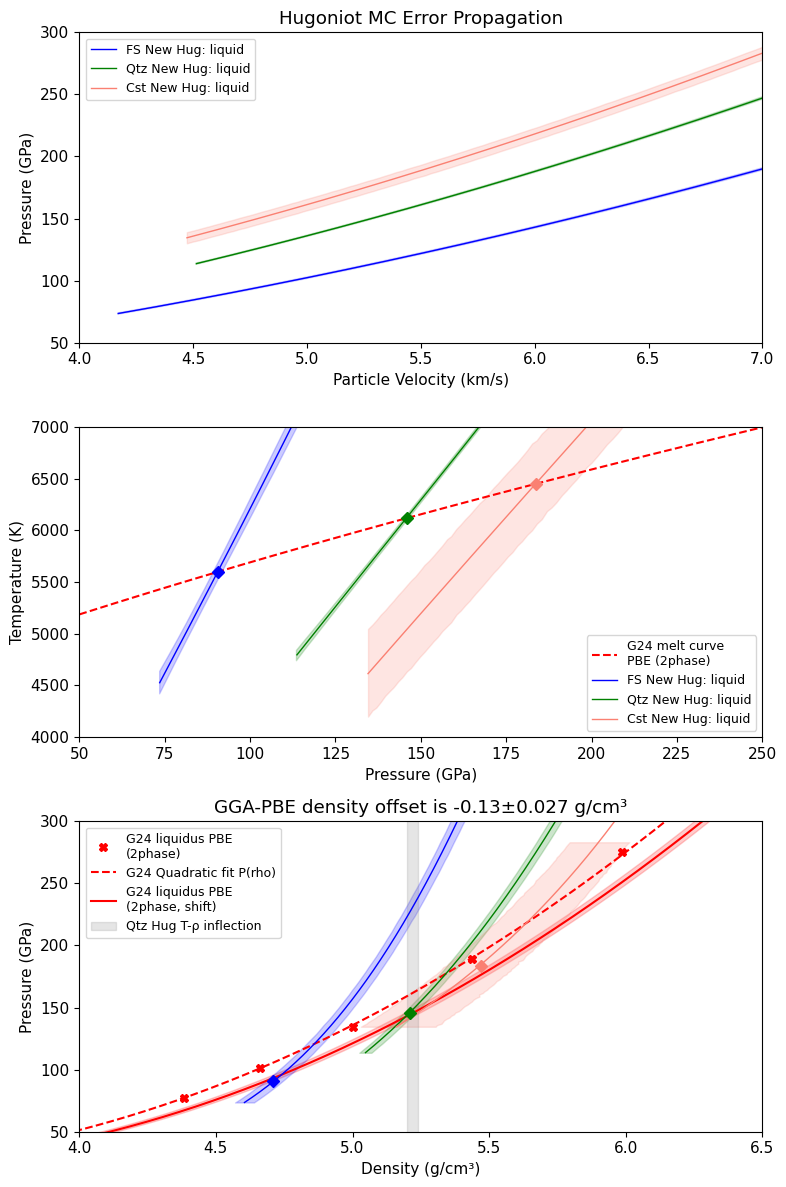

In [12]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(3, 1,figsize=(8,12))
plt.rcParams['lines.markersize'] = mks


whu=1

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
xi=0
ax[xi].plot(fs_hug_liq.up[indfs],fs_hug_liq.P[indfs],'b-',label='FS New Hug: liquid',linewidth=whu)
ax[xi].fill_between(fs_mc.up_ind,fs_mc.p_mean-fs_mc.p_std,fs_mc.p_mean+fs_mc.p_std,color='blue',alpha=.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.up[indqtz],qtz_hug_liq.P[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
ax[xi].fill_between(qtz_mc.up_ind,qtz_mc.p_mean-qtz_mc.p_std,qtz_mc.p_mean+fs_mc.p_std,color='green',alpha=.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.up[indcst],cst_hug_liq.P[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[xi].fill_between(cst_mc.up_ind,cst_mc.p_mean-cst_mc.p_std,cst_mc.p_mean+cst_mc.p_std,color='salmon',alpha=.2)
ax[xi].set_xlim(4,7)
ax[xi].set_ylim(50,300)
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Hugoniot MC Error Propagation')
#ax[xi].text(55,6650,'A')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'X',color='red',label=G24mclrho['lab']+'\n(2phase)')
res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)
xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
ax[xi].plot(xrho,ypres,'--',color='red',label='G24 Quadratic fit P(rho)')

#ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid+diff_mean,eosdat_list[G24mclrho['id']].P_liquid,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].plot(xrho+G24_rshift,ypres,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].fill_betweenx(ypres,xrho+G24_rshift-G24_rshift_std,xrho+G24_rshift+G24_rshift_std,color='red',alpha=0.2)


ax[xi].plot(fs_hug_liq.rho[indfs],fs_hug_liq.P[indfs],'b-',linewidth=1)#,label='FS Hugoniot')
ax[xi].fill_betweenx(fs_mc.p_mean,fs_mc.rho_mean-fs_mc.rho_std,fs_mc.rho_mean+fs_mc.rho_std,color='blue',alpha=.2)

ax[xi].plot(qtz_hug_liq.rho[indqtz],qtz_hug_liq.P[indqtz],'g-',linewidth=whu)#,label='Qtz Hugoniot')
ax[xi].fill_betweenx(qtz_mc.p_mean,qtz_mc.rho_mean-qtz_mc.rho_std,qtz_mc.rho_mean+qtz_mc.rho_std,color='green',alpha=.2)

ax[xi].plot(cst_hug_liq.rho[indcst],cst_hug_liq.P[indcst],'-',color='salmon',linewidth=whu)#,label='Cst Hugoniot')
ax[xi].fill_betweenx(cst_mc.p_mean,cst_mc.rho_mean-cst_mc.rho_std,cst_mc.rho_mean+cst_mc.rho_std,color='salmon',alpha=.2)
ax[xi].plot(fs_rho_cross,fs_PT_cross[0],'bD')
ax[xi].plot(qtz_rho_cross,qtz_PT_cross[0],'gD')
ax[xi].plot(cst_rho_cross,cst_PT_cross[0],'D',color='salmon')

ax[xi].fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2,label='Qtz Hug T-ρ inflection')


ax[xi].set_ylim(50,300)
ax[xi].set_xlim(4,6.5)
#ax[xi].text(4.1,225,'B')

ax[xi].set_title('GGA-PBE density offset is '+str(np.round(-G24_rshift,3))[:5]+'±'+str(np.round(G24_rshift_std,3))[:5]+' g/cm³')
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=1
ax[xi].plot(gm24mc.P,gm24mc.T,'r--',label='G24 melt curve\nPBE (2phase)')
indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.P[indfs],fs_hug_liq.T[indfs],'b-',label='FS New Hug: liquid',linewidth=1)
ax[xi].fill_between(fs_mc.p_mean,fs_mc.t_mean-fs_mc.t_std,fs_mc.t_mean+fs_mc.t_std,color='blue',alpha=0.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.P[indqtz],qtz_hug_liq.T[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
ax[xi].fill_between(qtz_mc.p_mean,qtz_mc.t_mean-qtz_mc.t_std,qtz_mc.t_mean+qtz_mc.t_std,color='green',alpha=0.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.P[indcst],cst_hug_liq.T[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[xi].fill_between(cst_mc.p_mean,cst_mc.t_mean-cst_mc.t_std,cst_mc.t_mean+cst_mc.t_std,color='salmon',alpha=0.2)
ax[xi].plot(fs_PT_cross[0],fs_PT_cross[1],'bD')
ax[xi].plot(qtz_PT_cross[0],qtz_PT_cross[1],'gD')
ax[xi].plot(cst_PT_cross[0],cst_PT_cross[1],'D',color='salmon')
ax[xi].set_xlim(50,250)
ax[xi].set_ylim(4000,7000)
ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
#ax[xi].text(55,6650,'A')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
plt.savefig(outputfigpath+'DFT-PBE-offset.pdf')
plt.savefig(figurefigpath+'DFT-PBE-offset.pdf')
plt.show()

(lda-vs-data)=
## DFT with LDA

DFT-LDA isotherm calculations from Karki et al. 2007. They provide a PVT thermal model for a portion of the liquid field.




<Figure size 800x600 with 0 Axes>

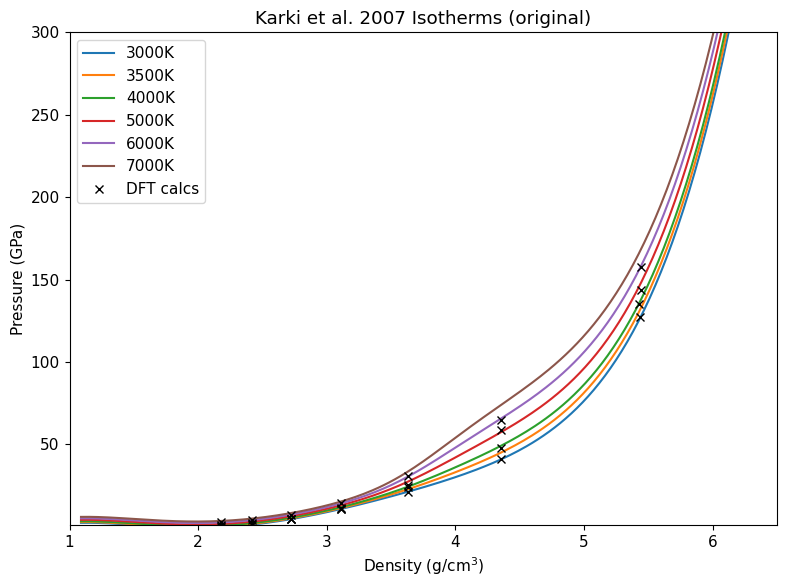

In [13]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
#fig, ax = plt.subplots(3, 1,figsize=fsize)
plt.rcParams['lines.markersize'] = mks


plt.figure(figsize=fsize)
#plt.rcParams.update({'font.size': 16})
plt.plot(karkiorig.rhoarr,karkiorig.p3000,'-',label='3000K')
plt.plot(karkiorig.rhoarr,karkiorig.p3500,'-',label='3500K')
plt.plot(karkiorig.rhoarr,karkiorig.p4000,'-',label='4000K')
plt.plot(karkiorig.rhoarr,karkiorig.p5000,'-',label='5000K')
plt.plot(karkiorig.rhoarr,karkiorig.p6000,'-',label='6000K')
plt.plot(karkiorig.rhoarr,karkiorig.p7000,'-',label='7000K')
plt.plot(karki.rho,karki.P,'kx',label='DFT calcs')
plt.ylim(1,300)
#plt.yscale("log")
plt.xlim(1,6.5)
plt.legend()
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
plt.title('Karki et al. 2007 Isotherms (original)')
plt.tight_layout()
#plt.savefig(outputfigpath+'K1-karki-dft-and-fits.pdf')
plt.show()

## Compare DFT and Hugoniots

DFT-LDA isotherm calculations from Karki et al. 2007. They provide a PVT thermal model for a portion of the liquid field.

The approach for comparison is to match the observed T-shock velocity relationship:
* For the known experimental PVT Hugoniot, for each T, calculate the Karki model isotherm.
* Find the density that satisfies the matching experimental P and T.


The comparison space is:
* T <= 6000 K
* P > temperature inversion on the Hugoniots
* ρ <= 5.5 g/cm3

This space is primarily the supercooled liquid shock wave front on the FS and Qtz Hugoniot (based on the PBE 2-phase melt curve). The Coesite Hugoniot liquid branch does not overlap with this space.


In [14]:
## Using the experimental Hugoniots PVT --> find the Karki model rho that corresponds to the P-T for each Hugoniot point
tmax = 16000
## Quartz Hugoniot
## compare the PVT relationships on the Z+Omega Hugoniots and Karki et al. 2007 liquid model
## region below 300 GPa
ind = np.where((qtz_hug_liq.T < tmax) & (qtz_hug_liq.P > qtz_wiggle_P2))[0]
#ind = np.where((qtz_hug_liq.rho <= 5.5))[0]
newqtzrhokarkiarr = np.zeros(len(qtz_hug_liq.P))
rho00=2.65 # qtz hugoniot initial density
for iii in ind:
    BV = 1.e-3*(10.4 - (9.5 / (1+np.exp((25.2-karkiorig.vaarr)/1.86)))) # GPa
    pthermt =  BV*(qtz_hug_liq.T[iii]-karkireftemporiginal) # karki thermal model reference temp 3000 K
    parrt = karkiorig.p3000+pthermt 
    ustmp = np.zeros(len(parrt))
    uptmp = np.zeros(len(parrt))
    itmp = np.where(parrt*(1/rho00-1/karkiorig.rhoarr)>0)[0]
    uptmp[itmp] = np.sqrt(parrt[itmp]*(1/rho00-1/karkiorig.rhoarr[itmp]))
    ustmp[itmp] = parrt[itmp]/rho00/uptmp[itmp]
    itmp = np.where((ustmp > 0) & (karkiorig.rhoarr > 3.2))[0]
    newqtzrhokarkiarr[iii] = np.interp(qtz_hug_liq.us[iii],ustmp[itmp],karkiorig.rhoarr[itmp])
    newqtzrhokarkiarr[iii] = np.interp(qtz_hug_liq.P[iii],parrt[itmp],karkiorig.rhoarr[itmp])

karkiorig.qtzrhotest = deepcopy(newqtzrhokarkiarr)
newqtzrhokarkiarr=[]

## Fused silica Hugoniot
## compare the PVT relationships on the Z+Omega Hugoniots and Karki et al. 2007 liquid model
## region below 300 GPa
ind = np.where((fs_hug_liq.T < tmax)  & (fs_hug_liq.P > fs_wiggle_P2))[0]
newfsrhokarkiarr = np.zeros(len(fs_hug_liq.P))
rho00=2.2 # qtz hugoniot initial density
for iii in ind:
    BV = 1.e-3*(10.4 - (9.5 / (1+np.exp((25.2-karkiorig.vaarr)/1.86)))) # GPa
    pthermt =  BV*(fs_hug_liq.T[iii]-karkireftemporiginal) # karki model reference temp
    parrt = karkiorig.p3000+pthermt 
    ustmp = np.zeros(len(parrt))
    uptmp = np.zeros(len(parrt))
    itmp = np.where(parrt*(1/rho00-1/karkiorig.rhoarr)>0)[0]
    uptmp[itmp] = np.sqrt(parrt[itmp]*(1/rho00-1/karkiorig.rhoarr[itmp]))
    ustmp[itmp] = parrt[itmp]/rho00/uptmp[itmp]
    itmp = np.where((ustmp > 0) & (karkiorig.rhoarr > 3.2))[0]
    newfsrhokarkiarr[iii] = np.interp(fs_hug_liq.us[iii],ustmp[itmp],karkiorig.rhoarr[itmp])
    newfsrhokarkiarr[iii] = np.interp(fs_hug_liq.P[iii],parrt[itmp],karkiorig.rhoarr[itmp])

karkiorig.fsrhotest = deepcopy(newfsrhokarkiarr)
newfsrhokarkiarr=[]


## Coesite Hugoniot
## compare the PVT relationships Coesite Hugoniots and Karki et al. 2007 liquid model
ind = np.where((cst_hug_liq.T < tmax)  & (cst_hug_liq.P > cst_wiggle_P2))[0]
#ind = np.where(cst_hug_liq.rho < 5.5)[0]
newcstrhokarkiarr = np.zeros(len(cst_hug_liq.P))
rho00=2.92 # qtz hugoniot initial density
for iii in ind:
    BV = 1.e-3*(10.4 - (9.5 / (1+np.exp((25.2-karkiorig.vaarr)/1.86)))) # GPa
    pthermt =  BV*(cst_hug_liq.T[iii]-karkireftemporiginal) # karki model reference temp
    parrt = karkiorig.p3000+pthermt 
    ustmp = np.zeros(len(parrt))
    uptmp = np.zeros(len(parrt))
    itmp = np.where(parrt*(1/rho00-1/karkiorig.rhoarr)>0)[0]
    uptmp[itmp] = np.sqrt(parrt[itmp]*(1/rho00-1/karkiorig.rhoarr[itmp]))
    ustmp[itmp] = parrt[itmp]/rho00/uptmp[itmp]
    itmp = np.where((ustmp > 0) & (karkiorig.rhoarr > 3.2))[0]
    newcstrhokarkiarr[iii] = np.interp(cst_hug_liq.us[iii],ustmp[itmp],karkiorig.rhoarr[itmp])
    newcstrhokarkiarr[iii] = np.interp(cst_hug_liq.P[iii],parrt[itmp],karkiorig.rhoarr[itmp])
    #print(cst_hug_liq.T[iii], cst_hug_liq.us[iii],newcstrhokarkiarr[iii],cst_hug_liq.rho[iii])
    if 0:
        plt.plot(karkiorig.rhoarr,karkiorig.p3000)
        plt.plot(karkiorig.rhoarr,parrt)
        plt.show()
        plt.plot(uptmp[itmp],ustmp[itmp])
        plt.show()
        plt.plot(karkiorig.rhoarr[itmp],ustmp[itmp])
        plt.plot(newcstrhokarkiarr[iii],cst_hug_liq.us[iii],'o')
        plt.show()
karkiorig.cstrhotest = deepcopy(newcstrhokarkiarr)
newcstrhokarkiarr=[]




In [15]:
# calculate offsets between Karki et al. 2007 LDA model and Hugoniots with uncertainties

Tmax = 6000

# Fused silica
# calculate weighted average for difference with Karki over range >wiggle_P2 and < 7000 K
#ind = np.where(fs_mc.p_mean > fs_wiggle_P2)[0]
#plt.fill_betweenx(fs_mc.p_mean[ind],fs_mc.rho_mean[ind]-fs_mc.rho_std[ind],fs_mc.rho_mean[ind]+fs_mc.rho_std[ind],color='blue',alpha=.2)

ind = np.where((fs_hug_liq.T < Tmax)  & (fs_hug_liq.P > fs_wiggle_P2))[0]
fsrhoerr = np.interp(fs_hug_liq.P[ind],fs_mc.p_mean,fs_mc.rho_std)
diff = karkiorig.fsrhotest[ind]-fs_hug_liq.rho[ind] # g/cm3
diff_std = fs_hug_liq.rho[ind]*fsrhoerr # quadrature std assuming no error on DFT
average = np.average(diff,weights = 1/diff_std)
average_std = np.average(diff_std)
print(average_std)
variance = np.average((diff-average)**2,weights=1/diff_std)
print(average,np.sqrt(variance))
fs_diff_avg = average
fs_diff_std = np.sqrt(variance)
fs_diff_avgstd = average_std

# Quartz
ind = np.where((qtz_hug_liq.T < Tmax)  & (qtz_hug_liq.P >qtz_wiggle_P2))[0]
qtzrhoerr = np.interp(qtz_hug_liq.P[ind],qtz_mc.p_mean,qtz_mc.rho_std)
diff = karkiorig.qtzrhotest[ind]-qtz_hug_liq.rho[ind] # g/cm3
diff_std = qtz_hug_liq.rho[ind]*qtzrhoerr # quadrature std assuming no error on DFT
average = np.average(diff,weights = 1/diff_std)
average_std = np.average(diff_std)
print(average_std)
variance = np.average((diff-average)**2,weights=1/diff_std)
print(average,np.sqrt(variance))
qtz_diff_avg = average
qtz_diff_std = np.sqrt(variance)
qtz_diff_avgstd = average_std

# combine these two measurements
average = np.average([fs_diff_avg,qtz_diff_avg],weights=1/np.asarray([fs_diff_std,qtz_diff_std]))
variance = np.average(([fs_diff_avg,qtz_diff_avg]-average)**2,weights=1/np.asarray([fs_diff_std,qtz_diff_std]))
variance = np.average(([fs_diff_avg,qtz_diff_avg]-average)**2,weights=1/np.asarray([fs_diff_avgstd,qtz_diff_avgstd]))
print(average,np.sqrt(variance))

diff_avg = average
diff_std = np.sqrt(variance)

0.1524539627708991
0.1440995581671211 0.0020524500663819385
0.11041704139930224
0.14834744684283627 0.0028375661168707723
0.1458824928380357 0.0022043309339084233


<Figure size 800x600 with 0 Axes>

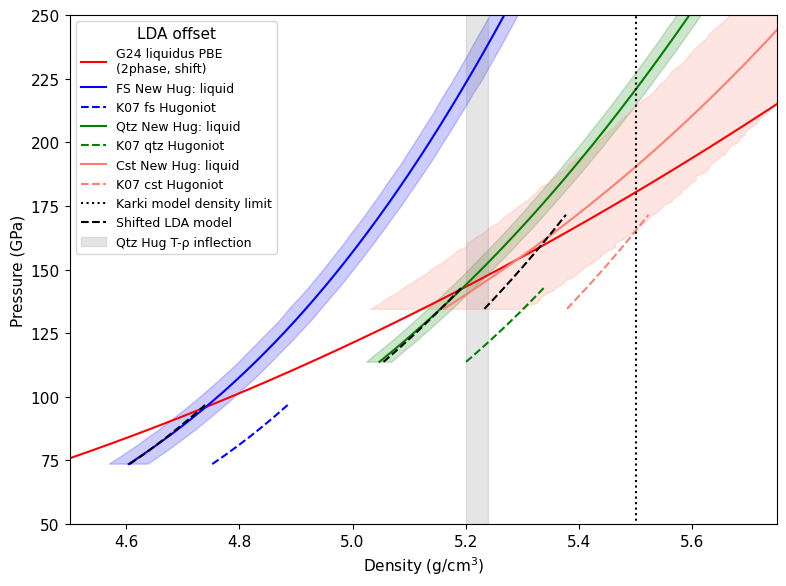

The formal error propagation for the density offset is small because the two independent measurements are almost identical in value.


In [16]:


%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
#fig, ax = plt.subplots(3, 1,figsize=fsize)
plt.rcParams['lines.markersize'] = mks
plt.figure(figsize=fsize)
#plt.rcParams.update({'font.size': 16})

#plt.figure(figsize=(6,6))
#plt.rcParams.update({'font.size': 16})
#krhoshift = -0.09
#krhoshift=0
plt.plot(xrho+G24_rshift,ypres,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
#plt.fill_betweenx(ypres,xrho+G24_rshift-G24_rshift_std,xrho+G24_rshift+G24_rshift_std,color='red',alpha=0.2)

# FUSED SILICA
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)[0]
plt.plot(fs_hug_liq.rho[ind],fs_hug_liq.P[ind],'b-',label='FS New Hug: liquid')
ind = np.where(fs_mc.p_mean > fs_wiggle_P2)[0]
plt.fill_betweenx(fs_mc.p_mean[ind],fs_mc.rho_mean[ind]-fs_mc.rho_std[ind],fs_mc.rho_mean[ind]+fs_mc.rho_std[ind],color='blue',alpha=.2)

ind = np.where((fs_hug_liq.T < Tmax)  & (fs_hug_liq.P > fs_wiggle_P2))[0]
plt.plot(karkiorig.fsrhotest[ind],fs_hug_liq.P[ind],'b--',label='K07 fs Hugoniot')
plt.plot(karkiorig.fsrhotest[ind]-diff_avg,fs_hug_liq.P[ind],'k--')
#plt.fill_betweenx(fs_hug_liq.P[ind],karkiorig.fsrhotest[ind]-diff_avg-diff_std,karkiorig.fsrhotest[ind]-diff_avg+diff_std,color='grey',alpha=1)


#plt.plot(karkiorig.fsrhotest+krhoshift,fs_hug_liq.P,'bP',label='Karki07 rho shift')

# QUARTZ
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)[0]
plt.plot(qtz_hug_liq.rho[ind],qtz_hug_liq.P[ind],'g-',label='Qtz New Hug: liquid')
ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)[0]
plt.fill_betweenx(qtz_mc.p_mean[ind],qtz_mc.rho_mean[ind]-qtz_mc.rho_std[ind],qtz_mc.rho_mean[ind]+qtz_mc.rho_std[ind],color='green',alpha=.2)

ind = np.where((qtz_hug_liq.T < Tmax)  & (qtz_hug_liq.P > qtz_wiggle_P2))[0]
plt.plot(karkiorig.qtzrhotest[ind],qtz_hug_liq.P[ind],'g--',label='K07 qtz Hugoniot')
plt.plot(karkiorig.qtzrhotest[ind]-diff_avg,qtz_hug_liq.P[ind],'k--')

# COESITE
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)[0]
plt.plot(cst_hug_liq.rho[ind],cst_hug_liq.P[ind],'-',color='salmon',label='Cst New Hug: liquid')
ind = np.where(cst_mc.p_mean > cst_wiggle_P2)[0]
plt.fill_betweenx(cst_mc.p_mean[ind],cst_mc.rho_mean[ind]-cst_mc.rho_std[ind],cst_mc.rho_mean[ind]+cst_mc.rho_std[ind],color='salmon',alpha=.2)

ind = np.where((cst_hug_liq.T < Tmax)  & (cst_hug_liq.P > cst_wiggle_P2))[0]
plt.plot(karkiorig.cstrhotest[ind],cst_hug_liq.P[ind],'--',color='salmon',label='K07 cst Hugoniot')
plt.plot(karkiorig.cstrhotest[ind]-diff_avg,cst_hug_liq.P[ind],'k--')

#plt.plot(karkiorig.qtzrhotest+krhoshift,qtz_hug_liq.P,'gP',label='Karki07 rho shift')
plt.ylim([50,250])
plt.xlim([4.5,5.75])
plt.plot([5.5,5.5],[0,250],'k:',label='Karki model density limit')
plt.plot([],[],'k--',label='Shifted LDA model')


plt.fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2,label='Qtz Hug T-ρ inflection')

#plt.title('LDA density offset is '+str(np.round(diff_avg,3))[:5]+'±'+str(np.round(diff_std,3))[:5]+' g/cm³ (FS & Qtz only)')

plt.legend(title='LDA offset',fontsize=lfss)#loc='center left', bbox_to_anchor=(1, 0.5))
#plt.title('Shock data vs. DFT original consistency check')
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
#plt.text(4.6,270,'A',fontsize=16)
plt.tight_layout()
plt.savefig(outputfigpath+'DFT-LDA-offset-PT.pdf')
plt.savefig(figurefigpath+'DFT-LDA-offset-PT.pdf')
plt.show()

print('The formal error propagation for the density offset is small because the two independent measurements are almost identical in value.')

## include model extrapolation

In [17]:
# calculate offsets between Karki et al. 2007 LDA model and Hugoniots with uncertainties

Tmax = 6000

# Fused silica
# calculate weighted average for difference with Karki over range >wiggle_P2 and < 7000 K
#ind = np.where(fs_mc.p_mean > fs_wiggle_P2)[0]
#plt.fill_betweenx(fs_mc.p_mean[ind],fs_mc.rho_mean[ind]-fs_mc.rho_std[ind],fs_mc.rho_mean[ind]+fs_mc.rho_std[ind],color='blue',alpha=.2)

ind = np.where((fs_hug_liq.T < Tmax)  & (fs_hug_liq.P > fs_wiggle_P2))[0]
fsrhoerr = np.interp(fs_hug_liq.P[ind],fs_mc.p_mean,fs_mc.rho_std)
diff = karkiorig.fsrhotest[ind]-fs_hug_liq.rho[ind] # g/cm3
diff_std = fs_hug_liq.rho[ind]*fsrhoerr # quadrature std assuming no error on DFT
average = np.average(diff,weights = 1/diff_std)
average_std = np.average(diff_std)
print(average_std)
variance = np.average((diff-average)**2,weights=1/diff_std)
print(average,np.sqrt(variance))
fs_diff_avg = average
fs_diff_std = np.sqrt(variance)
fs_diff_avgstd = average_std

# Quartz
ind = np.where((qtz_hug_liq.T < Tmax)  & (qtz_hug_liq.P >qtz_wiggle_P2))[0]
qtzrhoerr = np.interp(qtz_hug_liq.P[ind],qtz_mc.p_mean,qtz_mc.rho_std)
diff = karkiorig.qtzrhotest[ind]-qtz_hug_liq.rho[ind] # g/cm3
diff_std = qtz_hug_liq.rho[ind]*qtzrhoerr # quadrature std assuming no error on DFT
average = np.average(diff,weights = 1/diff_std)
average_std = np.average(diff_std)
print(average_std)
variance = np.average((diff-average)**2,weights=1/diff_std)
print(average,np.sqrt(variance))
qtz_diff_avg = average
qtz_diff_std = np.sqrt(variance)
qtz_diff_avgstd = average_std

# combine these two measurements
average = np.average([fs_diff_avg,qtz_diff_avg],weights=1/np.asarray([fs_diff_std,qtz_diff_std]))
variance = np.average(([fs_diff_avg,qtz_diff_avg]-average)**2,weights=1/np.asarray([fs_diff_std,qtz_diff_std]))
variance = np.average(([fs_diff_avg,qtz_diff_avg]-average)**2,weights=1/np.asarray([fs_diff_avgstd,qtz_diff_avgstd]))
print(average,np.sqrt(variance))

diff_avg = average
diff_std = np.sqrt(variance)
lda_shift = -diff_avg
lda_shift_std = np.sqrt(variance)
print('The weighted offset between Karki EOS model 2 Hugoniot crossings is:')
print('*** entry for define_eos.py ***')
print('lda_liquid_density_shift = ',-diff_avg,' # g/cm3')
print('lda_liquid_density_shift_std = ',np.sqrt(diff_std),' # g/cm3')
print('******')

0.1524539627708991
0.1440995581671211 0.0020524500663819385
0.11041704139930224
0.14834744684283627 0.0028375661168707723
0.1458824928380357 0.0022043309339084233
The weighted offset between Karki EOS model 2 Hugoniot crossings is:
*** entry for define_eos.py ***
lda_liquid_density_shift =  -0.1458824928380357  # g/cm3
lda_liquid_density_shift_std =  0.046950302809549836  # g/cm3
******


<Figure size 800x600 with 0 Axes>

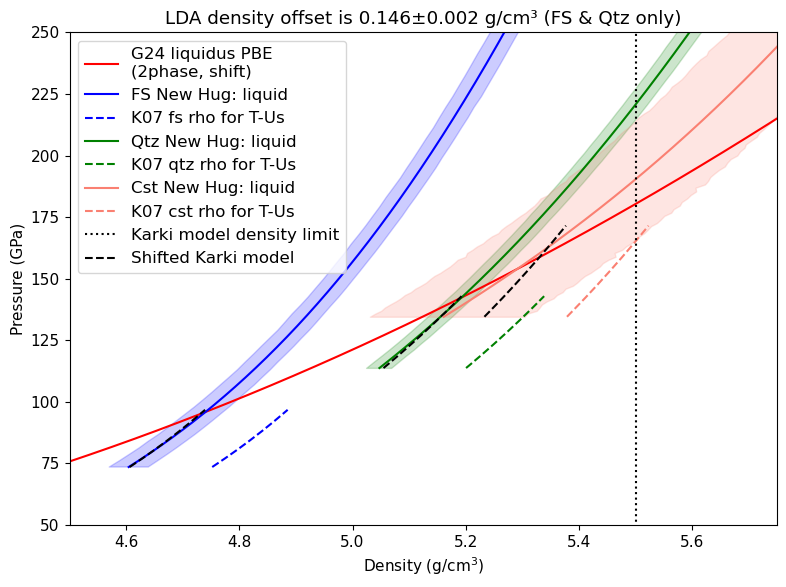

The formal error propagation for the density offset is small because the two independent measurements are almost identical in value.


In [18]:
Tmax=6000

%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
#fig, ax = plt.subplots(3, 1,figsize=fsize)
plt.rcParams['lines.markersize'] = mks
plt.figure(figsize=fsize)
#plt.rcParams.update({'font.size': 16})

#plt.figure(figsize=(6,6))
#plt.rcParams.update({'font.size': 16})
#krhoshift = -0.09
#krhoshift=0
plt.plot(xrho+G24_rshift,ypres,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
#plt.fill_betweenx(ypres,xrho+G24_rshift-G24_rshift_std,xrho+G24_rshift+G24_rshift_std,color='red',alpha=0.2)

# FUSED SILICA
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)[0]
plt.plot(fs_hug_liq.rho[ind],fs_hug_liq.P[ind],'b-',label='FS New Hug: liquid')
ind = np.where(fs_mc.p_mean > fs_wiggle_P2)[0]
plt.fill_betweenx(fs_mc.p_mean[ind],fs_mc.rho_mean[ind]-fs_mc.rho_std[ind],fs_mc.rho_mean[ind]+fs_mc.rho_std[ind],color='blue',alpha=.2)

ind = np.where((fs_hug_liq.T < Tmax)  & (fs_hug_liq.P > fs_wiggle_P2))[0]
plt.plot(karkiorig.fsrhotest[ind],fs_hug_liq.P[ind],'b--',label='K07 fs rho for T-Us')
plt.plot(karkiorig.fsrhotest[ind]-diff_avg,fs_hug_liq.P[ind],'k--')
#plt.fill_betweenx(fs_hug_liq.P[ind],karkiorig.fsrhotest[ind]-diff_avg-diff_std,karkiorig.fsrhotest[ind]-diff_avg+diff_std,color='grey',alpha=1)


#plt.plot(karkiorig.fsrhotest+krhoshift,fs_hug_liq.P,'bP',label='Karki07 rho shift')

# QUARTZ
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)[0]
plt.plot(qtz_hug_liq.rho[ind],qtz_hug_liq.P[ind],'g-',label='Qtz New Hug: liquid')
ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)[0]
plt.fill_betweenx(qtz_mc.p_mean[ind],qtz_mc.rho_mean[ind]-qtz_mc.rho_std[ind],qtz_mc.rho_mean[ind]+qtz_mc.rho_std[ind],color='green',alpha=.2)

ind = np.where((qtz_hug_liq.T < Tmax)  & (qtz_hug_liq.P > qtz_wiggle_P2))[0]
plt.plot(karkiorig.qtzrhotest[ind],qtz_hug_liq.P[ind],'g--',label='K07 qtz rho for T-Us')
plt.plot(karkiorig.qtzrhotest[ind]-diff_avg,qtz_hug_liq.P[ind],'k--')

# COESITE
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)[0]
plt.plot(cst_hug_liq.rho[ind],cst_hug_liq.P[ind],'-',color='salmon',label='Cst New Hug: liquid')
ind = np.where(cst_mc.p_mean > cst_wiggle_P2)[0]
plt.fill_betweenx(cst_mc.p_mean[ind],cst_mc.rho_mean[ind]-cst_mc.rho_std[ind],cst_mc.rho_mean[ind]+cst_mc.rho_std[ind],color='salmon',alpha=.2)

ind = np.where((cst_hug_liq.T < Tmax)  & (cst_hug_liq.P > cst_wiggle_P2))[0]
plt.plot(karkiorig.cstrhotest[ind],cst_hug_liq.P[ind],'--',color='salmon',label='K07 cst rho for T-Us')
plt.plot(karkiorig.cstrhotest[ind]-diff_avg,cst_hug_liq.P[ind],'k--')

#plt.plot(karkiorig.qtzrhotest+krhoshift,qtz_hug_liq.P,'gP',label='Karki07 rho shift')
plt.ylim([50,250])
plt.xlim([4.5,5.75])
plt.plot([5.5,5.5],[0,250],'k:',label='Karki model density limit')
plt.plot([],[],'k--',label='Shifted Karki model')

plt.title('LDA density offset is '+str(np.round(diff_avg,3))[:5]+'±'+str(np.round(diff_std,3))[:5]+' g/cm³ (FS & Qtz only)')

plt.legend(fontsize=12)#loc='center left', bbox_to_anchor=(1, 0.5))
#plt.title('Shock data vs. DFT original consistency check')
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
#plt.text(4.6,270,'A',fontsize=16)
plt.tight_layout()
plt.savefig(outputfigpath+'DFT-LDA-offset-PT.pdf')
plt.savefig(figurefigpath+'DFT-LDA-offset-PT.pdf')
plt.show()

print('The formal error propagation for the density offset is small because the two independent measurements are almost identical in value.')

## Figure for paper

<Figure size 800x600 with 0 Axes>

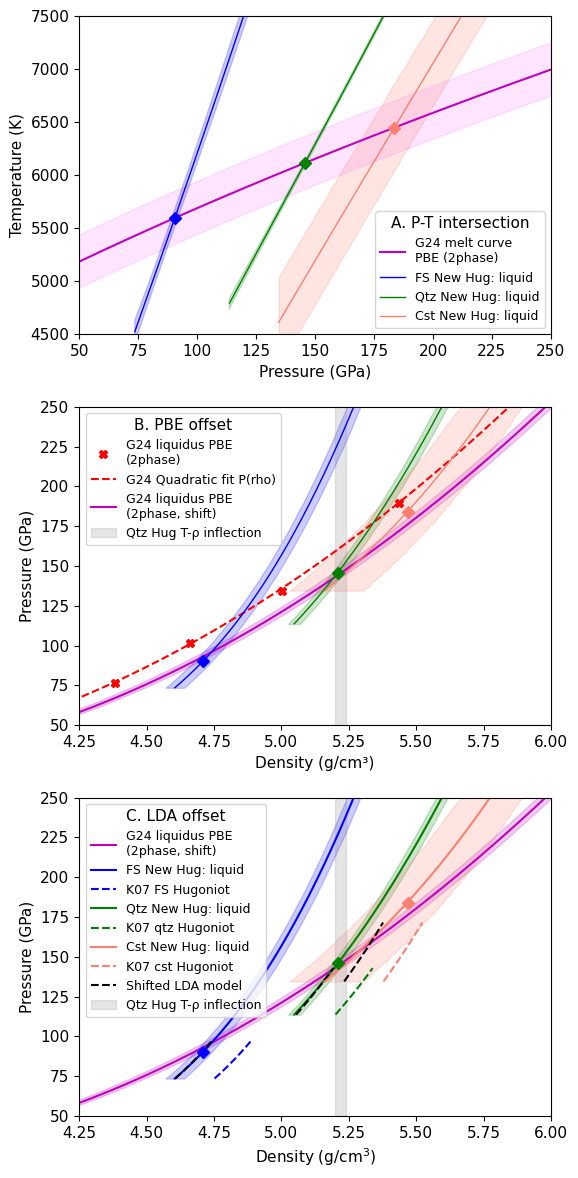

In [19]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(3, 1,figsize=(6,12))
plt.rcParams['lines.markersize'] = mks
#plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.size': 14})

whu=1

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)

if 0:
    xi=0
    ax[xi].plot(fs_hug_liq.up[indfs],fs_hug_liq.P[indfs],'b-',label='FS New Hug: liquid',linewidth=whu)
    ax[xi].fill_between(fs_mc.up_ind,fs_mc.p_mean-fs_mc.p_std,fs_mc.p_mean+fs_mc.p_std,color='blue',alpha=.2)
    indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
    ax[xi].plot(qtz_hug_liq.up[indqtz],qtz_hug_liq.P[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
    ax[xi].fill_between(qtz_mc.up_ind,qtz_mc.p_mean-qtz_mc.p_std,qtz_mc.p_mean+fs_mc.p_std,color='green',alpha=.2)
    indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
    ax[xi].plot(cst_hug_liq.up[indcst],cst_hug_liq.P[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
    ax[xi].fill_between(cst_mc.up_ind,cst_mc.p_mean-cst_mc.p_std,cst_mc.p_mean+cst_mc.p_std,color='salmon',alpha=.2)
    ax[xi].set_xlim(4,7)
    ax[xi].set_ylim(50,300)
    ax[xi].set_ylabel('Pressure (GPa)')
    ax[xi].set_xlabel('Particle Velocity (km/s)')
    #ax[xi].set_title('Hugoniot MC Error Propagation')
    #ax[xi].text(55,6650,'A')
    ax[xi].legend(fontsize=lfss)

xi=1
ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'X',color='red',label=G24mclrho['lab']+'\n(2phase)')
res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)
xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
ax[xi].plot(xrho,ypres,'--',color='red',label='G24 Quadratic fit P(rho)')

#ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid+diff_mean,eosdat_list[G24mclrho['id']].P_liquid,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].plot(xrho+G24_rshift,ypres,'-',color='m',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].fill_betweenx(ypres,xrho+G24_rshift-G24_rshift_std,xrho+G24_rshift+G24_rshift_std,color='m',alpha=0.2)

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.rho[indfs],fs_hug_liq.P[indfs],'b-',linewidth=1)#,label='FS Hugoniot')
ax[xi].fill_betweenx(fs_mc.p_mean,fs_mc.rho_mean-fs_mc.rho_std,fs_mc.rho_mean+fs_mc.rho_std,color='blue',alpha=.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.rho[indqtz],qtz_hug_liq.P[indqtz],'g-',linewidth=whu)#,label='Qtz Hugoniot')
ax[xi].fill_betweenx(qtz_mc.p_mean,qtz_mc.rho_mean-qtz_mc.rho_std,qtz_mc.rho_mean+qtz_mc.rho_std,color='green',alpha=.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.rho[indcst],cst_hug_liq.P[indcst],'-',color='salmon',linewidth=whu)#,label='Cst Hugoniot')
ax[xi].fill_betweenx(cst_mc.p_mean,cst_mc.rho_mean-cst_mc.rho_std,cst_mc.rho_mean+cst_mc.rho_std,color='salmon',alpha=.2)
ax[xi].plot(fs_rho_cross,fs_PT_cross[0],'bD')
ax[xi].plot(qtz_rho_cross,qtz_PT_cross[0],'gD')
ax[xi].plot(cst_rho_cross,cst_PT_cross[0],'D',color='salmon')

ax[xi].fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2,label='Qtz Hug T-ρ inflection')


ax[xi].set_ylim(50,250)
ax[xi].set_xlim(4.25,6.)
#ax[xi].text(4.1,225,'B')

#ax[xi].set_title('GGA-PBE density offset is '+str(np.round(-G24_rshift,3))[:5]+'±'+str(np.round(G24_rshift_std,3))[:5]+' g/cm³')
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(title='B. PBE offset',fontsize=lfss,title_fontsize=lfss+2)


xi=0
#ax[xi].plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Model melt curve')
#ax[xi].fill_between(stsmcsmooth.P,stsmcsmooth.T-stsmcsmooth.T_std,stsmcsmooth.T+stsmcsmooth.T_std,color='magenta',alpha=0.1)
ax[xi].plot(gm24mc.P,gm24mc.T,'m-',label='G24 melt curve\nPBE (2phase)')
ax[xi].fill_between(gm24mc.P,gm24mc.T-250,gm24mc.T+250,color='magenta',alpha=0.1)

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.P[indfs],fs_hug_liq.T[indfs],'b-',label='FS New Hug: liquid',linewidth=1)
indfs = np.where(fs_mc.p_mean > fs_wiggle_P2)
ax[xi].fill_between(fs_mc.p_mean[indfs],fs_mc.t_mean[indfs]-fs_mc.t_std[indfs],fs_mc.t_mean[indfs]+fs_mc.t_std[indfs],color='blue',alpha=0.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.P[indqtz],qtz_hug_liq.T[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
indqtz = np.where(qtz_mc.p_mean > qtz_wiggle_P2)
ax[xi].fill_between(qtz_mc.p_mean[indqtz],qtz_mc.t_mean[indqtz]-qtz_mc.t_std[indqtz],qtz_mc.t_mean[indqtz]+qtz_mc.t_std[indqtz],color='green',alpha=0.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.P[indcst],cst_hug_liq.T[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
indcst = np.where(cst_mc.p_mean > cst_wiggle_P2)
ax[xi].fill_between(cst_mc.p_mean[indcst],cst_mc.t_mean[indcst]-cst_mc.t_std[indcst],cst_mc.t_mean[indcst]+cst_mc.t_std[indcst],color='salmon',alpha=0.2)
ax[xi].plot(fs_PT_cross[0],fs_PT_cross[1],'bD')
ax[xi].plot(qtz_PT_cross[0],qtz_PT_cross[1],'gD')
ax[xi].plot(cst_PT_cross[0],cst_PT_cross[1],'D',color='salmon')
ax[xi].set_xlim(50,250)
ax[xi].set_ylim(4500,7500)
ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
#ax[xi].text(55,6650,'A')
ax[xi].legend(title='A. P-T intersection',fontsize=lfss,title_fontsize=lfss+2)


xi=2

ax[xi].plot(xrho+G24_rshift,ypres,'-',color='m',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].fill_betweenx(ypres,xrho+G24_rshift-G24_rshift_std,xrho+G24_rshift+G24_rshift_std,color='m',alpha=0.2)

# FUSED SILICA
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)[0]
ax[xi].plot(fs_hug_liq.rho[ind],fs_hug_liq.P[ind],'b-',label='FS New Hug: liquid')
ind = np.where(fs_mc.p_mean > fs_wiggle_P2)[0]
ax[xi].fill_betweenx(fs_mc.p_mean[ind],fs_mc.rho_mean[ind]-fs_mc.rho_std[ind],fs_mc.rho_mean[ind]+fs_mc.rho_std[ind],color='blue',alpha=.2)

ind = np.where((fs_hug_liq.T < Tmax)  & (fs_hug_liq.P > fs_wiggle_P2))[0]
ax[xi].plot(karkiorig.fsrhotest[ind],fs_hug_liq.P[ind],'b--',label='K07 FS Hugoniot')
ax[xi].plot(karkiorig.fsrhotest[ind]-diff_avg,fs_hug_liq.P[ind],'k--')
#ax[xi].fill_betweenx(fs_hug_liq.P[ind],karkiorig.fsrhotest[ind]-diff_avg-diff_std,karkiorig.fsrhotest[ind]-diff_avg+diff_std,color='grey',alpha=1)


#ax[xi].plot(karkiorig.fsrhotest+krhoshift,fs_hug_liq.P,'bP',label='Karki07 rho shift')

# QUARTZ
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)[0]
ax[xi].plot(qtz_hug_liq.rho[ind],qtz_hug_liq.P[ind],'g-',label='Qtz New Hug: liquid')
ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)[0]
ax[xi].fill_betweenx(qtz_mc.p_mean[ind],qtz_mc.rho_mean[ind]-qtz_mc.rho_std[ind],qtz_mc.rho_mean[ind]+qtz_mc.rho_std[ind],color='green',alpha=.2)

ind = np.where((qtz_hug_liq.T < Tmax)  & (qtz_hug_liq.P > qtz_wiggle_P2))[0]
ax[xi].plot(karkiorig.qtzrhotest[ind],qtz_hug_liq.P[ind],'g--',label='K07 qtz Hugoniot')
ax[xi].plot(karkiorig.qtzrhotest[ind]-diff_avg,qtz_hug_liq.P[ind],'k--')

# COESITE
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)[0]
ax[xi].plot(cst_hug_liq.rho[ind],cst_hug_liq.P[ind],'-',color='salmon',label='Cst New Hug: liquid')
ind = np.where(cst_mc.p_mean > cst_wiggle_P2)[0]
ax[xi].fill_betweenx(cst_mc.p_mean[ind],cst_mc.rho_mean[ind]-cst_mc.rho_std[ind],cst_mc.rho_mean[ind]+cst_mc.rho_std[ind],color='salmon',alpha=.2)

ind = np.where((cst_hug_liq.T < Tmax)  & (cst_hug_liq.P > cst_wiggle_P2))[0]
ax[xi].plot(karkiorig.cstrhotest[ind],cst_hug_liq.P[ind],'--',color='salmon',label='K07 cst Hugoniot')
ax[xi].plot(karkiorig.cstrhotest[ind]-diff_avg,cst_hug_liq.P[ind],'k--')

#ax[xi].plot(karkiorig.qtzrhotest+krhoshift,qtz_hug_liq.P,'gP',label='Karki07 rho shift')
ax[xi].set_ylim([50,250])
ax[xi].set_xlim([4.25,6])
#ax[xi].plot([5.5,5.5],[0,250],'k:',label='Karki model density limit')
ax[xi].plot([],[],'k--',label='Shifted LDA model')

ax[xi].plot(fs_rho_cross,fs_PT_cross[0],'bD')
ax[xi].plot(qtz_rho_cross,qtz_PT_cross[0],'gD')
ax[xi].plot(cst_rho_cross,cst_PT_cross[0],'D',color='salmon')
ax[xi].fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2,label='Qtz Hug T-ρ inflection')

#ax[xi].title('LDA density offset is '+str(np.round(diff_avg,3))[:5]+'±'+str(np.round(diff_std,3))[:5]+' g/cm³ (FS & Qtz only)')

ax[xi].legend(title='C. LDA offset',fontsize=lfss,title_fontsize=lfss+2)#loc='center left', bbox_to_anchor=(1, 0.5))
#ax[xi].title('Shock data vs. DFT original consistency check')
ax[xi].set_xlabel(r'Density (g/cm$^3$)')
ax[xi].set_ylabel('Pressure (GPa)')

fig.tight_layout()
plt.savefig(outputfigpath+'FIG-DFT-PBE-offset.pdf')
plt.savefig(figurefigpath+'FIG-DFT-PBE-offset.pdf')
plt.show()

## What if quartz temperature calibration is systematically wrong?

In [34]:
res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)
xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
#plt.plot(xrho,ypres,'--',color='red',label='G24 Quadratic fit P(rho)')
#plt.show()

print('calculate Hugoniot intersection with PBE melt curve in PV')
print('phase, (density, pressure, temperature) on Hugoniot, temperature on PBE calc, dT')
x,y = intersection(xrho,ypres,fs_hug_liq.rho,fs_hug_liq.P)
t=np.interp(y,fs_hug_liq.P,fs_hug_liq.T)
tg24 = np.interp(y,gm24mc.P,gm24mc.T)
print('fs', x,y,t,tg24,t-tg24)

x,y = intersection(xrho,ypres,qtz_hug_liq.rho,qtz_hug_liq.P)
t=np.interp(y,qtz_hug_liq.P,qtz_hug_liq.T)
tg24 = np.interp(y,gm24mc.P,gm24mc.T)
print('qtz', x,y,t,tg24,t-tg24)

x,y = intersection(xrho,ypres,cst_hug_liq.rho,cst_hug_liq.P)
t=np.interp(y,cst_hug_liq.P,cst_hug_liq.T)
tg24 = np.interp(y,gm24mc.P,gm24mc.T)
print('cst', x,y,t,tg24,t-tg24)


calculate Hugoniot intersection with PBE melt curve in PV
phase, (density, pressure, temperature) on Hugoniot, temperature on PBE calc, dT
fs [4.85954129] [120.62058617] [7562.21691418] [5886.06455465] [1676.15235953]
qtz [5.34185996] [177.2752886] [7427.83780894] [6394.50243367] [1033.33537528]
cst [5.63643647] [218.16233574] [7724.77925944] [6738.74445792] [986.03480152]


## CHECK THAT EOS DEFINITION MATCHES

In [21]:
print('Check dft offsets in EOS model. Should be zeros/very small.')
print(pbe_shift-pbe_liquid_density_shift)
print(lda_shift-lda_liquid_density_shift)


Check dft offsets in EOS model. Should be zeros/very small.
0.00016940776941221092
0.0001907106280042148


## Park et al. 2025

[120. 140. 160. 180. 200. 220. 240. 260.]
[4.89 5.08 5.25 5.41 5.56 5.7  5.83 5.95]


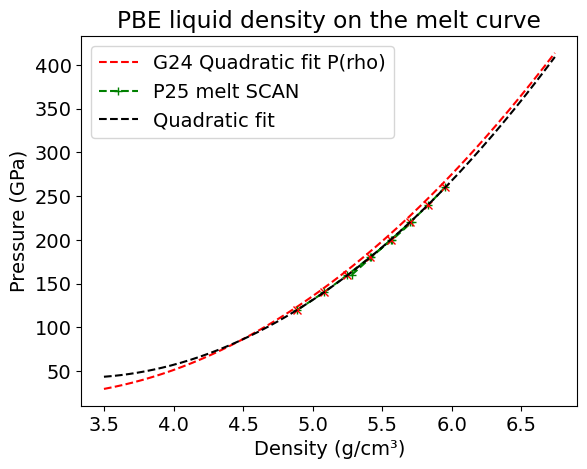

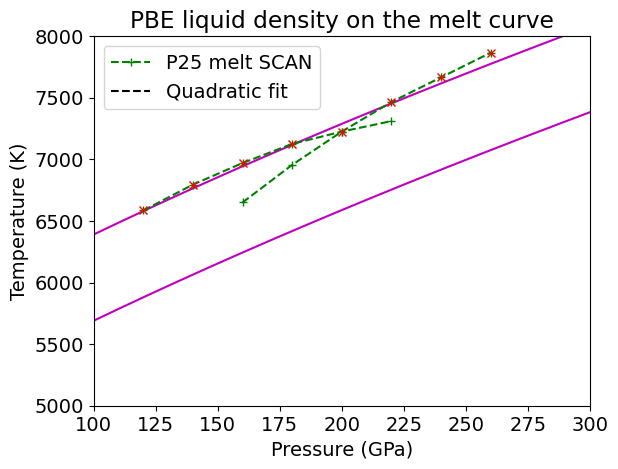

In [22]:

#plt.plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'x--',color='red',label=G24mclrho['lab']+'\n(2phase, Fig. 2A)')
#plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-')
plt.plot(eosdat_list[P25mcscan['id']].rho_l,eosdat_list[P25mcscan['id']].P,'+--',color='g',label=P25mcscan['lab'])

ind = np.asarray([1,2,3,4,10,11,12,13])
P25rho_l = eosdat_list[P25mcscan['id']].rho_l[ind]
P25P = eosdat_list[P25mcscan['id']].P[ind]
P25T = eosdat_list[P25mcscan['id']].T[ind]
print(P25P)
print(P25rho_l)
plt.plot(P25rho_l,P25P,'rx')

plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')

#res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)
res = np.polyfit(P25rho_l,P25P,2)
xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
plt.plot(xrho,ypres,'k--',label='Quadratic fit')
plt.title('PBE liquid density on the melt curve')
plt.legend()
plt.show()


#plt.plot(eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].T_liquid,'x--',color='red',label=G24mclrho['lab']+'\n(2phase, Fig. 2A)')

plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-')
plt.plot(stsmcsmooth.P,stsmcsmooth.T+700,'m-')
plt.plot(eosdat_list[P25mcscan['id']].P,eosdat_list[P25mcscan['id']].T,'+--',color='g',label=P25mcscan['lab'])
plt.plot(P25P,P25T,'rx')
plt.ylabel('Temperature (K)')
plt.xlabel('Pressure (GPa)')
plt.xlim([100,300])
plt.ylim(5000,8000)

plt.plot(xrho,ypres,'k--',label='Quadratic fit')
plt.title('PBE liquid density on the melt curve')
plt.legend()
plt.show()

In [23]:

# find where P-T crosses
fs_PT_cross = intersection(gm24mc.P,gm24mc.T,fs_hug_liq.P,fs_hug_liq.T)
qtz_PT_cross = intersection(gm24mc.P,gm24mc.T,qtz_hug_liq.P,qtz_hug_liq.T)
cst_PT_cross = intersection(gm24mc.P,gm24mc.T,cst_hug_liq.P,cst_hug_liq.T)


In [24]:

fs_rho_cross = np.interp(fs_PT_cross[0],fs_mc.p_mean,fs_mc.rho_mean)
qtz_rho_cross = np.interp(qtz_PT_cross[0],qtz_mc.p_mean,qtz_mc.rho_mean)
cst_rho_cross = np.interp(cst_PT_cross[0],cst_mc.p_mean,cst_mc.rho_mean)

# find the rho error from MC model above (assume P is true for the moment)
fs_rho_cross_std = np.interp(fs_PT_cross[0],fs_mc.p_mean,fs_mc.rho_std)
qtz_rho_cross_std = np.interp(qtz_PT_cross[0],qtz_mc.p_mean,qtz_mc.rho_std)
cst_rho_cross_std = np.interp(cst_PT_cross[0],cst_mc.p_mean,cst_mc.rho_std)
print(fs_rho_cross,fs_rho_cross_std)
print(qtz_rho_cross,qtz_rho_cross_std)
print(cst_rho_cross,cst_rho_cross_std)

# Fig 2 Geng et al. 2024 model densities
fs_rho_model = np.interp(fs_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)
qtz_rho_model = np.interp(qtz_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)
cst_rho_model = np.interp(cst_PT_cross[0],eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid)

fs_rho_model = np.interp(fs_PT_cross[0],ypres,xrho)
qtz_rho_model = np.interp(qtz_PT_cross[0],ypres,xrho)
cst_rho_model = np.interp(cst_PT_cross[0],ypres,xrho)

print(fs_rho_cross-fs_rho_model)
print(qtz_rho_cross-qtz_rho_model)
print(cst_rho_cross-cst_rho_model)

diff_arr = np.asarray([fs_rho_cross-fs_rho_model,qtz_rho_cross-qtz_rho_model,cst_rho_cross-cst_rho_model])
diff_mean = np.mean(diff_arr)
diff_std = np.std(diff_arr)
print(diff_mean,diff_std)

diff_arr = np.asarray([fs_rho_cross-fs_rho_model,qtz_rho_cross-qtz_rho_model,cst_rho_cross-cst_rho_model])
diff_std = np.asarray([fs_rho_cross*fs_rho_cross_std,qtz_rho_cross*qtz_rho_cross_std,cst_rho_cross*cst_rho_cross_std])
print(1/diff_std)
#diff_wt  = np.asarray([1/fs_rho_cross_std,1/qtz_rho_cross_std,1/cst_rho_cross_std])
#print(diff_wt)
diff_wt = 1/diff_std
diff_mean = np.average(diff_arr,weights=diff_wt,returned=True)
print(diff_mean,1/diff_mean[1])
#diff_std = np.std(diff_arr)
#print(diff_mean,diff_std)

values = diff_arr
weights=diff_wt
average = np.average(values, weights=weights)
# Fast and numerically precise:
variance = np.average((values-average)**2, weights=weights)
print(average, np.sqrt(variance))
print(average/np.sqrt(variance))

print('The weighted offset between GM24 and the 3 Hugoniot crossings is:')
print('*** entry for define_eos.py ***')
print('pbe_liquid_density_shift = ',average,' # g/cm3')
print('pbe_liquid_density_shift_std = ',np.sqrt(variance),' # g/cm3')
print('******')

G24_rshift = average
G24_rshift_std = np.sqrt(variance)
pbe_shift = average
pbe_shift_std = np.sqrt(variance)

[4.71065657] [0.03185438]
[5.20863689] [0.02105791]
[5.46904871] [0.12695238]
[0.15781695]
[0.07670751]
[0.03010016]
0.08820820955047488 0.0527705351851488
[[6.66422146]
 [9.11718266]
 [1.44028142]]
(np.float64(0.10419631861153442), np.float64(17.22168554230001)) 0.058066325595354414
0.10419631861153442 0.04440483312980554
2.3465085052103363
The weighted offset between GM24 and the 3 Hugoniot crossings is:
*** entry for define_eos.py ***
pbe_liquid_density_shift =  0.10419631861153442  # g/cm3
pbe_liquid_density_shift_std =  0.04440483312980554  # g/cm3
******


<Figure size 800x600 with 0 Axes>

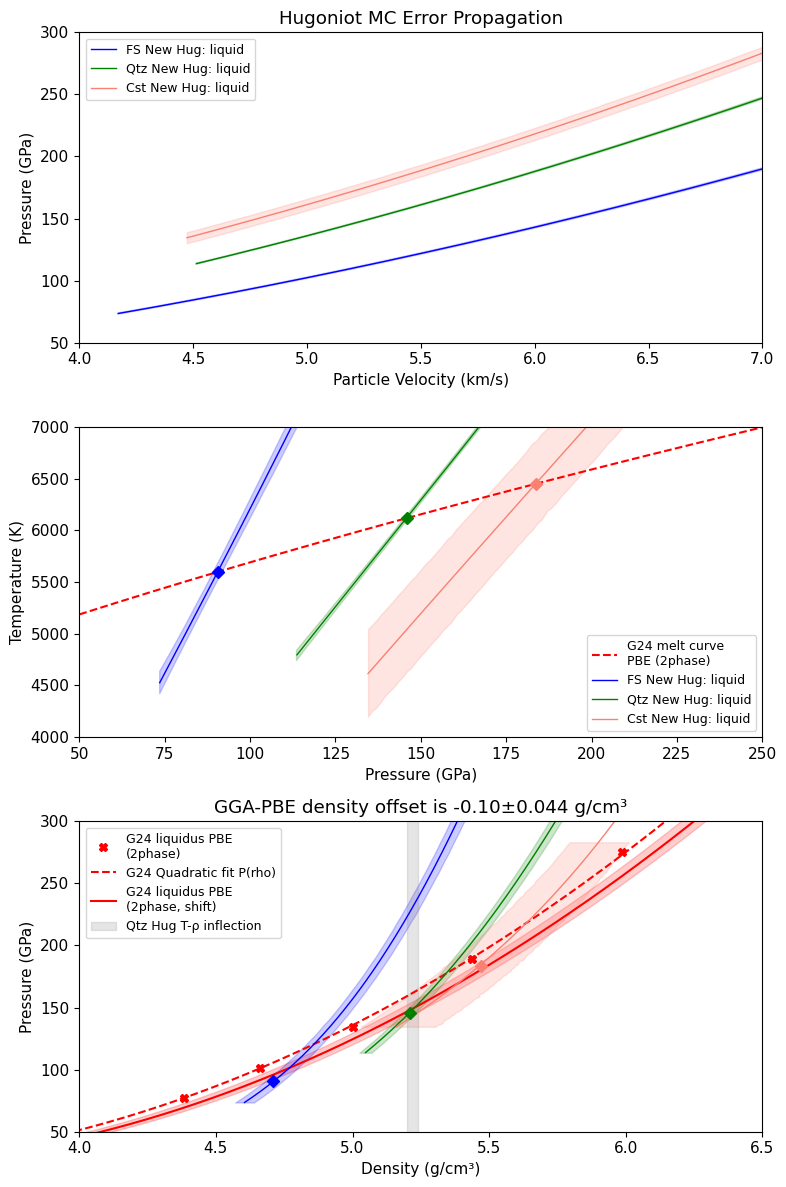

In [25]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(3, 1,figsize=(8,12))
plt.rcParams['lines.markersize'] = mks


whu=1

indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
xi=0
ax[xi].plot(fs_hug_liq.up[indfs],fs_hug_liq.P[indfs],'b-',label='FS New Hug: liquid',linewidth=whu)
ax[xi].fill_between(fs_mc.up_ind,fs_mc.p_mean-fs_mc.p_std,fs_mc.p_mean+fs_mc.p_std,color='blue',alpha=.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.up[indqtz],qtz_hug_liq.P[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
ax[xi].fill_between(qtz_mc.up_ind,qtz_mc.p_mean-qtz_mc.p_std,qtz_mc.p_mean+fs_mc.p_std,color='green',alpha=.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.up[indcst],cst_hug_liq.P[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[xi].fill_between(cst_mc.up_ind,cst_mc.p_mean-cst_mc.p_std,cst_mc.p_mean+cst_mc.p_std,color='salmon',alpha=.2)
ax[xi].set_xlim(4,7)
ax[xi].set_ylim(50,300)
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Hugoniot MC Error Propagation')
#ax[xi].text(55,6650,'A')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,'X',color='red',label=G24mclrho['lab']+'\n(2phase)')
res = np.polyfit(eosdat_list[G24mclrho['id']].rho_liquid,eosdat_list[G24mclrho['id']].P_liquid,2)
xrho = np.arange(3.5,6.75,.01)
ypres = res[2]+res[1]*xrho+res[0]*xrho*xrho
ax[xi].plot(xrho,ypres,'--',color='red',label='G24 Quadratic fit P(rho)')

#ax[xi].plot(eosdat_list[G24mclrho['id']].rho_liquid+diff_mean,eosdat_list[G24mclrho['id']].P_liquid,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].plot(xrho+G24_rshift,ypres,'-',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
ax[xi].fill_betweenx(ypres,xrho+G24_rshift-G24_rshift_std,xrho+G24_rshift+G24_rshift_std,color='red',alpha=0.2)


ax[xi].plot(fs_hug_liq.rho[indfs],fs_hug_liq.P[indfs],'b-',linewidth=1)#,label='FS Hugoniot')
ax[xi].fill_betweenx(fs_mc.p_mean,fs_mc.rho_mean-fs_mc.rho_std,fs_mc.rho_mean+fs_mc.rho_std,color='blue',alpha=.2)

ax[xi].plot(qtz_hug_liq.rho[indqtz],qtz_hug_liq.P[indqtz],'g-',linewidth=whu)#,label='Qtz Hugoniot')
ax[xi].fill_betweenx(qtz_mc.p_mean,qtz_mc.rho_mean-qtz_mc.rho_std,qtz_mc.rho_mean+qtz_mc.rho_std,color='green',alpha=.2)

ax[xi].plot(cst_hug_liq.rho[indcst],cst_hug_liq.P[indcst],'-',color='salmon',linewidth=whu)#,label='Cst Hugoniot')
ax[xi].fill_betweenx(cst_mc.p_mean,cst_mc.rho_mean-cst_mc.rho_std,cst_mc.rho_mean+cst_mc.rho_std,color='salmon',alpha=.2)
ax[xi].plot(fs_rho_cross,fs_PT_cross[0],'bD')
ax[xi].plot(qtz_rho_cross,qtz_PT_cross[0],'gD')
ax[xi].plot(cst_rho_cross,cst_PT_cross[0],'D',color='salmon')

ax[xi].fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2,label='Qtz Hug T-ρ inflection')


ax[xi].set_ylim(50,300)
ax[xi].set_xlim(4,6.5)
#ax[xi].text(4.1,225,'B')

ax[xi].set_title('GGA-PBE density offset is '+str(np.round(-G24_rshift,3))[:5]+'±'+str(np.round(G24_rshift_std,3))[:5]+' g/cm³')
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=1
ax[xi].plot(gm24mc.P,gm24mc.T,'r--',label='G24 melt curve\nPBE (2phase)')
indfs = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.P[indfs],fs_hug_liq.T[indfs],'b-',label='FS New Hug: liquid',linewidth=1)
ax[xi].fill_between(fs_mc.p_mean,fs_mc.t_mean-fs_mc.t_std,fs_mc.t_mean+fs_mc.t_std,color='blue',alpha=0.2)
indqtz = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.P[indqtz],qtz_hug_liq.T[indqtz],'g-',label='Qtz New Hug: liquid',linewidth=whu)
ax[xi].fill_between(qtz_mc.p_mean,qtz_mc.t_mean-qtz_mc.t_std,qtz_mc.t_mean+qtz_mc.t_std,color='green',alpha=0.2)
indcst = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.P[indcst],cst_hug_liq.T[indcst],'-',color='salmon',label='Cst New Hug: liquid',linewidth=whu)
ax[xi].fill_between(cst_mc.p_mean,cst_mc.t_mean-cst_mc.t_std,cst_mc.t_mean+cst_mc.t_std,color='salmon',alpha=0.2)
ax[xi].plot(fs_PT_cross[0],fs_PT_cross[1],'bD')
ax[xi].plot(qtz_PT_cross[0],qtz_PT_cross[1],'gD')
ax[xi].plot(cst_PT_cross[0],cst_PT_cross[1],'D',color='salmon')
ax[xi].set_xlim(50,250)
ax[xi].set_ylim(4000,7000)
ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
#ax[xi].text(55,6650,'A')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
plt.savefig(outputfigpath+'DFT-PBE-offset-P25.pdf')
plt.savefig(figurefigpath+'DFT-PBE-offset-P25.pdf')
plt.show()